### Data Quality & Preprocessing 

### Objective 

This notebook performs data-quality assessment and preprocessing on the Spotify Global Chart Totals & Lyrics dataset.

The preprocessing workflow includes:

- Schema validation
- Duplicate investigation
- Missing-value analysis
- `t10` missingness investigation
- `x?` parsing
- Artist and song-name cleaning
- Lyrics cleaning
- Numerical validation
- Outlier investigation
- Creation of a clean analytical dataset

### Important Principle

The dataset contains lifetime aggregate chart-performance variables. Theerfore, preprocessing decisions must preserve legitimate historical records and avoid introducing target leakage.

No machine-learning modeling is performed in this notebook.


In [1]:
# Imports

import os
import re
import warnings 

import numpy as np 
import pandas as pd 
import matplotlib.pyplot as pyplot
import seaborn as sns 

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")



In [2]:
# Load Raw Dataset

DATA_PATH =  "../data/raw/spotify_global_chart_totals_lyrics.csv"

df = pd.read_csv(DATA_PATH)

print(f"Dataset shape: {df.shape}")

Dataset shape: (8058, 10)


In [3]:
# Create a Working copy - This is important because we don't want to accidently modify the raw dataset

df_clean = df.copy()

print(f"Raw dataset shape : {df.shape}")
print(f"Working dataset shape: {df_clean.shape}")

Raw dataset shape : (8058, 10)
Working dataset shape: (8058, 10)


In [4]:
# Validate Columns

expected_columns = [
    "artist and title",
    "wks",
    "t10",
    "pk",
    "x?",
    "PkStreams",
    "total",
    "artist name",
    "song name",
    "lyrics"
]


missing_expected = [
    col for col in expected_columns
    if col not in df_clean.columns
]

unexpected_columns = [
    col for col in df_clean.columns
    if col not in expected_columns
]


print("Missing expected columns:", missing_expected)
print("Unexpected columns:", unexpected_columns)

Missing expected columns: []
Unexpected columns: []


1. Duplicate Investigation

We found earlier:

1) 0 complete duplicate rows
2) 232 duplicate artist-song combinations

We should not remove those 232 rows automatically

In [5]:
# Identify Duplicate Artist-Song Records

duplicate_mask = df_clean.duplicated(
    subset=["artist name", "song name"],
    keep=False
)

# Create dataframe containing all rows belonging to duplicate groups
duplicate_artist_song = (
    df_clean.loc[duplicate_mask]
    .sort_values(
        ["artist name", "song name", "wks"]
    )
)

print(f"Rows belonging to duplicate artist- song groups: {len(duplicate_artist_song)}")

duplicate_artist_song.head(20)

Rows belonging to duplicate artist- song groups: 444


,artist and title,wks,t10,pk,x?,PkStreams,total,artist name,song name,lyrics
4227,4batz - act ii: date @ 8,2,NaN,55,NaN,14488042,24862884,4batz,act ii: date @ 8,You want me to pull up? I'll come and slide by...
3024,4batz - act ii: date @ 8,6,NaN,132,NaN,9707311,54188571,4batz,act ii: date @ 8,You want me to pull up? I'll come and slide by...
3042,A Great Big World - Say Something,29,NaN,29,NaN,2923728,53471527,A Great Big World,Say Something,"Say something, I'm giving up on you I'll be th..."
2627,A Great Big World - Say Something,34,6.00,7,NaN,4468700,73725928,A Great Big World,Say Something,"Say something, I'm giving up on you I'll be th..."
8007,AFROJACK - SummerThing!,2,NaN,201,NaN,455368,648236,AFROJACK,SummerThing!,"I don't wanna write this love song I, I'm figh..."
5086,AFROJACK - SummerThing!,10,NaN,114,NaN,1918482,15127973,AFROJACK,SummerThing!,"I don't wanna write this love song I, I'm figh..."
4793,ANOTR - Talk To You,2,NaN,178,NaN,9048950,17914955,ANOTR,Talk To You,Let me take you higher So I can show you love ...
2865,ANOTR - Talk To You (ft. 54 Ultra),6,NaN,66,NaN,11575102,60953532,ANOTR,Talk To You,Let me take you higher So I can show you love ...
4847,Alesso - Heroes (we could be),5,NaN,48,NaN,4093426,17405115,Alesso,Heroes,We could hide away in daylight We go undercove...
1504,Alesso - Heroes (we could be),52,NaN,11,NaN,7138967,182118979,Alesso,Heroes,We could hide away in daylight We go undercove...


In [6]:
# Examine Duplicate Groups

duplicate_groups = (
    duplicate_artist_songs
    .groupby(["artist name", "song name"])
    .size()
    .sort_values(ascending=False)
)

duplicate_groups.head()

NameError: name 'duplicate_artist_songs' is not defined

In [ ]:
# Compare Performance of Duplicates

duplicate_artist_songs[
    [
        "artist name",
        "song name",
        "wks",
        "t10",
        "pk",
        "x?",
        "PkStreams",
        "total"
    ]
].head(50)

,artist name,song name,wks,t10,pk,x?,PkStreams,total
4227,4batz,act ii: date @ 8,2,NaN,55,NaN,14488042,24862884
3024,4batz,act ii: date @ 8,6,NaN,132,NaN,9707311,54188571
3042,A Great Big World,Say Something,29,NaN,29,NaN,2923728,53471527
2627,A Great Big World,Say Something,34,6.00,7,NaN,4468700,73725928
8007,AFROJACK,SummerThing!,2,NaN,201,NaN,455368,648236
5086,AFROJACK,SummerThing!,10,NaN,114,NaN,1918482,15127973
4793,ANOTR,Talk To You,2,NaN,178,NaN,9048950,17914955
2865,ANOTR,Talk To You,6,NaN,66,NaN,11575102,60953532
4847,Alesso,Heroes,5,NaN,48,NaN,4093426,17405115
1504,Alesso,Heroes,52,NaN,11,NaN,7138967,182118979


If the same artist/ song appears multiple times with different performance values, we should preserve those records unless we establish that they are accidental duplicates.

If the records are exact repetitions apart from formatting, then deduplication may be appropriate.

In [ ]:
print("Complete duplicate rows:", df_clean.duplicated().sum())

Complete duplicate rows: 0


In [ ]:
# Investigate Missing artist_name 

missing_artist = df_clean[
    df_clean["artist name"].isna()
]

missing_artist

,artist and title,wks,t10,pk,x?,PkStreams,total,artist name,song name,lyrics
4283,Various Artists -,1,NaN,13,NaN,24026707,24026707,NaN,Various Artists -,NaN
5647,Dj Ozuna -,1,NaN,32,NaN,10597738,10597738,NaN,Dj Ozuna -,(Yeah) Woh-oh-oh (Yeah) Tell me what you gonna...


In [ ]:
# Inspect Artist Information
# If the artist can clearly be identified from artist and title, we can fill it.

missing_artist[
    [
        "artist and title",
        "artist name",
        "song name",
        "lyrics"
    ]
]

,artist and title,artist name,song name,lyrics
4283,Various Artists -,NaN,Various Artists -,NaN
5647,Dj Ozuna -,NaN,Dj Ozuna -,(Yeah) Woh-oh-oh (Yeah) Tell me what you gonna...


In [ ]:
# Recover Missing Artist Names
# Rather than blindly splitting every row, only handle the two missing records.

def extract_artist_from_combined(value):
    if pd.isna(value):
        return np.nan 

    if " - " in value:
        return value.split(" - ", 1)[0].strip()

    return np.nan 

In [ ]:
# Diagnostic Cell

print(type(df))
print(type(df_clean))

<class 'pandas.DataFrame'>
<class 'pandas.DataFrame'>


In [ ]:
# Restore df_clean 

df_clean = df.copy()

print(type(df_clean))
print(df_clean.copy)

<class 'pandas.DataFrame'>
<bound method NDFrame.copy of                          artist and title  wks   t10   pk     x?  PkStreams  \
0            The Weeknd - Blinding Lights  347 64.00    1  (x13)   52375259   
1               Ed Sheeran - Shape of You  424 34.00    1  (x14)   64217796   
2                Harry Styles - As It Was  218 60.00    1  (x11)   78460903   
3     The Neighbourhood - Sweater Weather  333   NaN   16    NaN   21624450   
4       Lewis Capaldi - Someone You Loved  343 15.00    4    NaN   24962682   
...                                   ...  ...   ...  ...    ...        ...   
8053              Mariah Carey - Infinity    1   NaN  220    NaN     177495   
8054     Twenty One Pilots - Fairly Local    1   NaN  234    NaN     176713   
8055                Ludacris - Good Lovin    1   NaN  223    NaN     174256   
8056                       iSHi - Push It    1   NaN  236    NaN     173886   
8057               Handsome Ghost - Steps    1   NaN  239    NaN     16691

In [ ]:
# Check the missing artist records
missing_artist = df_clean[df_clean["artist name"].isna()]

print("Missing artist names: {len(missing_artist)}")

missing_artist[
    ["artist and title", "artist name", "song name"]
]

Missing artist names: {len(missing_artist)}


,artist and title,artist name,song name
4283,Various Artists -,NaN,Various Artists -
5647,Dj Ozuna -,NaN,Dj Ozuna -


In [ ]:
# Extract artist name from "artist and title"
for idx in missing_artist.index:

    combined = str(df_clean.loc[idx, "artist and title"])

    if " - " in combined:
        artist = combined.split(" - ", 1)[0].strip()
        df_clean.loc[idx, "artist name"] = str(artist)

In [ ]:
print(
    "Remaining missing artist names:",
    df_clean["artist name"].isna().sum()
)

Remaining missing artist names: 2


In [ ]:
df_clean.loc[
    missing_artist.index,
    ["artist and title", "artist name", "song name"]
]

,artist and title,artist name,song name
4283,Various Artists -,NaN,Various Artists -
5647,Dj Ozuna -,NaN,Dj Ozuna -


In [ ]:
# Manually recover the two msising artist names
df_clean.loc[4283, "artist name"] = "Various Artists"
df_clean.loc[5647, "artist name"] = "Dj Ozuna"

In [ ]:
# Verify

print(
    "Remaining missing artist names:",
    df_clean["artist name"].isna().sum()
)

Remaining missing artist names: 0


In [ ]:
# Verify the records

df_clean.loc[
    [4283, 5647],
    ["artist and title", "artist name", "song name"]
]

,artist and title,artist name,song name
4283,Various Artists -,Various Artists,Various Artists -
5647,Dj Ozuna -,Dj Ozuna,Dj Ozuna -


In [ ]:
# Investigate Missing Lyrics

missing_lyrics = df_clean[
    df_clean["lyrics"].isna() |
    df_clean["lyrics"].astype(str).str.strip().eq("")
]

print(f"Missing/empty lyrics records: {len(missing_lyrics)}")

missing_lyrics[
    ["artist name", "song name", "lyrics"]
]

Missing/empty lyrics records: 15


,artist name,song name,lyrics
2400,BTS,No. 29,NaN
3111,Unknown Artist,Medusa,NaN
3389,Vicetone,Astronomia,NaN
3440,Vigiland,UFO,NaN
4283,Various Artists,Various Artists -,NaN
5620,Drake,Intro,NaN
6053,SAMUKA,MONTAGEM,NaN
6351,Kygo,ID,NaN
6463,Lady Gaga,Chromatica II,NaN
6565,Lady Gaga,Chromatica I,NaN


In [ ]:
# Standardize Missing Lyrics

df_clean["lyrics"] = (
    df_clean["lyrics"]
    .fillna("")
    .astype(str)
    .str.strip()
)

print("Empty lyrics:", df_clean["lyrics"].eq("").sum())

Empty lyrics: 15


In [ ]:
# Create a Lyrics Availability Flag
# Add a flag so we can distinguish songs with lyrics from songs without lyrics

df_clean["lyrics_available"] = (
    df_clean["lyrics"].str.len() > 0
)

df_clean["lyrics_available"].value_counts()

lyrics_available
True     8043
False      15
Name: count, dtype: int64

In [ ]:
# Calculate the percentages

lyrics_availability = (
    df_clean["lyrics_available"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

lyrics_availability

lyrics_available
True    99.81
False    0.19
Name: proportion, dtype: float64

In [ ]:
# Next Section: t10

print("Total records:", len(df_clean))
print("t10 available:", df_clean["t10"].notna().sum())
print("t10 missing:", df_clean["t10"].isna().sum())


print(
    "t10 missing percentage",
    df_clean["t10"].isna().mean() * 100
)

Total records: 8058
t10 available: 810
t10 missing: 7248
t10 missing percentage 89.94787788533135


In [ ]:
df_clean["t10_available"] = df_clean["t10"].notna()

t10_comparison = (
    df_clean
    .groupby("t10_available")[
        ["wks","pk","PkStreams","total"]
    ]
    .agg(["count","mean","median","min", "max"])
)

t10_comparison

wks                          pk                        \
              count  mean median min  max count  mean median min  max   
t10_available                                                           
False          7248 10.99   3.00   1  425  7248 92.48  84.00  11  246   
True            810 56.00  44.00   2  457   810  4.81   4.00   1   10   

              PkStreams                                                 total  \
                  count          mean        median      min        max count   
t10_available                                                                   
False              7248  9,296,211.67  8,325,402.00   166910   60899507  7248   
True                810 31,888,948.90 28,690,398.50  3262177  128896137   810   

                                                                   
                        mean         median       min         max  
t10_available                                                      
False          82,939,085.48  21,921,941.50    166910  4142643719  
True          669,769,845.61 475,375,574.50  32007197  5441240333

The separation is very large. 

Songs with recorded t10 values:

1) spent substantially more time on the chart
2) generally reached much higher chart positions
3) accumulated substantially more peak streams
4) and accumulated much higher lifetime chart streams

Meanwhile, songs with missing t10 have a median of only 3 weeks and a median peak position of 84.

Important conclusion for preprocessing
We should not automatically treat missing t10 as ordinary random missing data.

The pattern strongly suggests that t10 may represent a conditional metric - likely something recorded only for songs that reached the Top 10 - rather than a field that is simply missing randomly.

However, we should not yet replace missing t10 with 0 until we verify the dataset's t10 definition/source 

For the preprocessing notebook, i recommend

In [ ]:
# Preserve original missingness

df_clean["t10_available"] = df_clean["t10"].notna()

print(df_clean["t10_available"].value_counts())

t10_available
False    7248
True      810
Name: count, dtype: int64


And keep t10 unchanged for now.

Why this matters for the ML Project.

This particularly important because t10 is strongly related to wks, pk, and total.

If we later build a model predicting something like chart longevity, using t10 could introduce leakage depending on when the prediction is supposed to be made.

For example:

Descriptive analysis:
t10 can be analyzed as a historical chart-performance variable

Predictive model:
We need to define exactly what information would have been available at prediction time before deciding whether t10 is a vlaid feature.

That's a good methodological point to document in the project


In [ ]:
# Next step: investigate t10 semantics
# Let's see what the available t10 values actually look like.

print("Unique t10 values:")
print(sorted(df_clean["t10"].dropna().unique())[:50])

print("\nValue counts:")
print(df_clean["t10"].value_counts().sort_index().head(30))

Unique t10 values:
[np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0), np.float64(9.0), np.float64(10.0), np.float64(11.0), np.float64(12.0), np.float64(13.0), np.float64(14.0), np.float64(15.0), np.float64(16.0), np.float64(17.0), np.float64(18.0), np.float64(19.0), np.float64(20.0), np.float64(21.0), np.float64(22.0), np.float64(23.0), np.float64(24.0), np.float64(25.0), np.float64(26.0), np.float64(27.0), np.float64(28.0), np.float64(29.0), np.float64(30.0), np.float64(31.0), np.float64(32.0), np.float64(33.0), np.float64(34.0), np.float64(36.0), np.float64(37.0), np.float64(40.0), np.float64(41.0), np.float64(42.0), np.float64(43.0), np.float64(49.0), np.float64(60.0), np.float64(61.0), np.float64(64.0), np.float64(71.0)]

Value counts:
t10
1.00     209
2.00      79
3.00      53
4.00      46
5.00      37
6.00      32
7.00      34
8.00      35
9.00      15
10.00     22
11.00     22
12.00     22
13.0

In [ ]:
t10_check = (
    df_clean[df_clean["t10"].notna()]
    [["artist name", "song name", "wks", "t10", "pk", "PkStreams", "total"]]
    .sort_values("t10", ascending=False)
)

t10_check.head(20)

,artist name,song name,wks,t10,pk,PkStreams,total
6,Billie Eilish,BIRDS OF A FEATHER,114,71.00,1,66726270,3821072735
0,The Weeknd,Blinding Lights,347,64.00,1,52375259,5441240333
7,Lady Gaga,Die With A Smile,101,61.00,1,78624101,3797546382
2,Harry Styles,As It Was,218,60.00,1,78460903,4417264164
60,sombr,back to friends,70,49.00,1,42212664,1998294246
12,The Kid LAROI,Stay,188,43.00,1,70502410,3402050072
47,Mariah Carey,All I Want for Christmas Is You,92,42.00,1,92506541,2117164649
32,Tones And I,Dance Monkey,151,41.00,1,52055226,2538070349
89,Lil Nas X,INDUSTRY BABY,81,40.00,2,53085371,1632867564
16,Glass Animals,Heat Waves,205,37.00,1,31668100,3112973333


In [ ]:
# Then check whether t10 is always associated with a Top-10 peak

print(
    "Available t10 where pk <= 10:",
    ((df_clean["t10"].notna()) & (df_clean["pk"] <= 10)).sum()
)

print(
    "Available t10 where pk > 10:",
    ((df_clean["t10"].notna()) & (df_clean["pk"] > 10)).sum()
)

Available t10 where pk <= 10: 810
Available t10 where pk > 10: 0


In [ ]:
# One more important validation 

print(
    "Missing t10 but pk <= 10:",
    ((df_clean["t10"].isna()) & (df_clean["pk"] <= 10)).sum()
)

Missing t10 but pk <= 10: 0


Conclusion: t10 missing values represent zero Top-10 weeks

The validation gives us three decisive results.

All 810 non-missing t10 records have pk <= 10.
0 non-missing t10 records have pk > 10.
0 missing t10 records have pk <= 10.

So the dataset follows this pattern.

If a song reached the Top 10 - t10 contains the number of weeks spent in the Top 10.
If a song never reached the Top 10 - t10 is missing 

Therefore, the missingness is structural, not ordinary missing data.



In [ ]:
# Convert t10 missing values at zero

# Missing t10 means the song never reached the Top 10
df_clean["t10"] = df_clean["t10"].fillna(0)

# Convert to integer because Top 10 weeks are whole numbers
df_clean["t10"] = df_clean["t10"].astype(int)

print("Missing t10:", df_clean["t10"].isna().sum())
print("t10 dtype:", df_clean["t10"].dtype)

print("\nt10 distribution:")
print(df_clean["t10"].value_counts().sort_index().head(20))

Missing t10: 0
t10 dtype: int64

t10 distribution:
t10
0     7248
1      209
2       79
3       53
4       46
5       37
6       32
7       34
8       35
9       15
10      22
11      22
12      22
13      24
14      27
15      24
16      12
17      11
18      15
19      10
Name: count, dtype: int64


Yoc can retain t10_available as an audit field if you want, but i recommend not using it as a modeling feature because after this discovery it is essentially a Top-10 indicator.

In [ ]:
# Add a more meaningful feature - Since t10 has a clear interpretation, create:

df_clean["top10_reached"] = (df_clean["t10"] > 0).astype(int)

print(df_clean["top10_reached"].value_counts())

top10_reached
0    7248
1     810
Name: count, dtype: int64


This gives us a very useful binary feature:

0 -> Never reached Top 10
1 -> Reached Top 10

In [ ]:
# Important validation - Let's verify the relationship one final time

t10_validation = pd.crosstab(
    df_clean["top10_reached"],
    df_clean["pk"] <= 10
)

t10_validation

pk,False,True
top10_reached,,
0,7248,0
1,0,810


One important modeling warning - There is a subtle issue here that will matter later

Because top10_reached = 1 - pk <= 10 

top10_reached and pk contain essentially the same information.

Likewise, t10 is a historical chart-performance measure, not an independent characteristic of the song.

so:

For EDA
We can absolutely analyze:
t10, top10_reached, pk, wks, total, PkStreams

For predictive modeling
We need to decide what exactly we're predicting and at what point in time before using these variables.

For example, preicting lifetime total using wks and t10 would have substantial target leakage because those variables describe the song's completed chart history.

This distinction will make your project much stronger from a Data Science portfolio perspective.

#### `t10` Missing-Value Investigation

The `t10` column contains 810 non-null values and 7,248 missing values.

Validation showed that:

- All 810 non-null `t10` records have `pk <= 10`.
- No non-null 't10` records have `pk > 10`.
- No missing `t10` records have `pk <= 10`.

Therefore, missing `t10` values represent songs that never reached the Top 10 rather than randomly missing observations.

The missing values were therefore converted to `0`, where:

-`t10 = 0` - the song never reached the Top 10
-`t10 > 0` - number of weeks the song spent in the Top 10

A derived `top10_reached` indicator was also created.

This treatment preserves the underlying meaning of the dataset and avoids inappropriate statistical imputation.

# Next Preprocessing task

Now that t10 is resolved, don't move to outlier removal yet.

The next important field is x?, because we need to determine exactly what values such as (x1), (x11) and (x13) represent and convert that column into the cleaner peak_duration feature.

Let's handle x? as a proper data-quality investigation, rather than immediately converting it. The goal is to understand what the field represents, validate whether the values are internally consistent, and only then create a clean feature

From our dataset inspection, x? is:

1) Present in only 334 of 8,058 records
2) Missing in 7,724 records (~95.9%)
3) Contains encoded values such as (x1), (x11), (x13)
4) Has 16 unique non-null values
5) The most frequent value is (x1)

Because the meaning of x? isn't explicitly documented in the schema, we should treat this as a unknown encoded source field until validation confirms its meaning.


Data Quality Task: Decode and Validate x?

Objective:
We want to accomplish four things:

1.Understand what values exist in x?.
2. Decode the (xN) format into a numeric function
3. Validate whether that feature is logically consistent with other chart metrics
4. Preserve the original x? column for traceability.



In [ ]:
# Step 1- Profile the x? column

print("Column:", "x?")
print("Data type:", df_clean["x?"].dtype)
print("Total records:", len(df_clean))

print("\nNon-null values:", df_clean["x?"].notna().sum())
print("Missing values:", df_clean["x?"].isna().sum())

print(
    "Missing percentage:",
    df_clean["x?"].isna().mean() * 100
)


print(
    "Unique non-null values:",
    df_clean["x?"].nunique()
)

Column: x?
Data type: str
Total records: 8058

Non-null values: 334
Missing values: 7724
Missing percentage: 95.85505088111194
Unique non-null values: 16


Why are we doing this?

Before transforming a column, we need to understand its completness and cardinality.

In this case, the important observation is that x? is extremely sparse.

Approximately 334 available & 7724 missing - So this isn't a feature we should blindly impute.



In [ ]:
# Examine the actual encoded values

x_values = (
    df_clean["x?"]
    .dropna()
    .value_counts()
    .sort_index()
)

print(x_values)

x?
(x1)     147
(x10)      6
(x11)      5
(x12)      3
(x13)      2
(x14)      4
(x17)      2
(x2)      55
(x3)      38
(x30)      1
(x4)      26
(x5)      13
(x6)      10
(x7)      10
(x8)       8
(x9)       4
Name: count, dtype: int64


In [ ]:
# Also inspect the raw values directly:

print(
    df_clean["x?"]
    .dropna()
    .unique()
)

<ArrowStringArray>
['(x13)', '(x14)', '(x11)',  '(x6)',  '(x3)', '(x30)',  '(x2)', '(x12)',
 '(x10)',  '(x5)',  '(x9)',  '(x1)', '(x17)',  '(x4)',  '(x7)',  '(x8)']
Length: 16, dtype: str


Why? - We want to establish the format of the encoding. 

For example, if we see (x1),(x2),(x3)....(x13) then there is evidence that the number inside parenthses is meaningful.

However, we shouldn't assume that (x13) means "13 weeks" untill we validate it against the other variables.

In [ ]:
# Inspect the records containing x?

# Instead of looking at the encoded values, look at the songs associated with them.

x_records = df_clean[
    df_clean["x?"].notna()
][
    [
        "artist name",
        "song name",
        "wks",
        "t10",
        "pk",
        "x?",
        "PkStreams",
        "total"
    ]
].sort_values(
    ["x?","wks"]
)

x_records.head(50)

,artist name,song name,wks,t10,pk,x?,PkStreams,total
2199,The Weeknd,Die For You,2,2,2,(x1),54891152,101104522
2377,Taylor Swift,ME!,3,3,2,(x1),37826059,88477470
2180,Playboi Carti,EVIL J0RDAN,5,1,2,(x1),43887601,102413695
1409,Sam Smith,Too Good At Goodbyes,8,8,1,(x1),30706135,197619743
1762,Travis Scott,K-POP,8,2,3,(x1),33693139,148410249
1842,Taylor Swift,Now That We Don't Talk,8,1,2,(x1),39935856,138651995
2098,Kendrick Lamar,N95,8,1,3,(x1),37163341,109732617
2320,Eminem,The Ringer,8,1,3,(x1),30918553,91694733
1151,Olivia Rodrigo,the cure,9,7,2,(x1),40707911,250788555
1215,Taylor Swift,Elizabeth Taylor,9,3,3,(x1),85348366,233721100


In [ ]:
# You can also inspect the longest-charting examples

x_records.sort_values(
    "wks",
    ascending=False
).head(20)

,artist name,song name,wks,t10,pk,x?,PkStreams,total
22,OneRepublic,Counting Stars,424,24,3,(x5),11170130,2739753518
1,Ed Sheeran,Shape of You,424,34,1,(x14),64217796,4470842634
0,The Weeknd,Blinding Lights,347,64,1,(x13),52375259,5441240333
8,Post Malone,Sunflower,346,31,1,(x2),34579416,3793341693
45,Hozier,Take Me To Church,326,20,1,(x5),13212580,2192969374
11,Drake,One Dance,325,26,1,(x14),47782311,3414508398
5,The Weeknd,Starboy,317,21,1,(x6),35360281,3857210959
137,John Legend,All of Me,310,15,3,(x2),8733114,1278923495
28,The Chainsmokers,Something Just Like This,303,12,2,(x2),33173199,2600142113
38,The Chainsmokers,Closer,271,28,1,(x11),46300740,2416616961


Why?

this is data profiling through contextual inspection.

Suppose we something like

song        wks     pk      x?
Song A      20      1       (x3)
Song B      40      1       (x8)
Song C      50      2       (x10)

That can help us understand whether x? behaves like a duration/count variable

In [ ]:
# Decode the (xN) format
# Once we've confirmed the pattern, create a new feature

df_clean["peak_duration"] = (
    df_clean["x?"]
    .astype("string")
    .str.extract(
        r"\(x(\d+)\)",
        expand=False
    )
)

df_clean["peak_duration"] = pd.to_datetime(
    df_clean["peak_duration"],
    errors="coerce"
)

Why create a new column?
Do not overwrite x?.

The original column is part of the raw source data. Keeping it gives us:
traceability, reproducibility, ability to revisit our interpretation, protection against accidental transformation errors.

So we have:

Raw Source                  Clean analytical feature

x?                          peak_duration
(x1)                        1
(x11)                       11
(x13)                       13
NaN                         NaN






In [ ]:
# Step 5 - Validate the extraction - Now make sure the transformation actually worked

print("peak_duration dtype:")
print(df_clean["peak_duration"].dtype)

print("\nNon-null peak_duration:")
print(df_clean["peak_duration"].notna().sum())

print("\nMissing peak duration:")
print(df_clean["peak_duration"].isna().sum())

print("\nUnique peak_duration values:")
print(
    sorted(
        df_clean["peak_duration"]
        .dropna()
        .unique()
    )
)

peak_duration dtype:
datetime64[s]

Non-null peak_duration:
0

Missing peak duration:
8058

Unique peak_duration values:
[]


What are we checking?

We want to confirm

x? non-null count = peak_duration non-null count

if x? has 334 usable records, peak_duration should also have 334 usable records

if those counts differ, our extraction rule needs investigation.

In [ ]:
# Check for malformed x? values - This is a good data-quality check
# Our extraction pattern expects: (x<number>) - Let's find anything that doesn't follow that pattern

non_null_x = df_clean[
    df_clean["x?"].notna()
].copy()

valid_x_pattern = non_null_x["x?"].astype("string").str.match(
    r"^\(x\d+\)$"
)

print("Valid x? format:", valid_x_pattern.sum())
print("Invalid x? format:", (~valid_x_pattern).sum())

print("\nInvalid values:")
print(
    non_null_x.loc[
        ~valid_x_pattern,
        "x?"
    ].unique()
)

Valid x? format: 334
Invalid x? format: 0

Invalid values:
<ArrowStringArray>
[]
Length: 0, dtype: str


This prevents a situation where something like 
x1
(x1
(x1)
(xabc)
gets silently converted incorrectly.

This is an important difference between cleaning and blind parsing.

In [ ]:
# Check numerical validity - Now examine the new feature

print(df_clean["peak_duration"].describe())

count      0
mean     NaT
min      NaT
25%      NaT
50%      NaT
75%      NaT
max      NaT
Name: peak_duration, dtype: object


In [ ]:
print(
    "Minimum peak duration:",
    df_clean["peak_duration"].min()
)

print(
    "Maximum peak duration:",
    df_clean["peak_duration"].max()
)

Minimum peak duration: NaT
Maximum peak duration: NaT


In [ ]:
print(
    df_clean["peak_duration"]
    .value_counts()
    .sort_index()
)

Series([], Name: count, dtype: int64)


We're checking for impossible or suspicious values such as:

0, negative numbers, extremely large values, unexpected decimal values

Because duration is a count of weeks, we expect whole positive integers.

In [ ]:
# Verify the current dtypes

print(df_clean[["wks","t10","pk","peak_duration","PkStreams","total"]].dtypes)

wks                      int64
t10                      int64
pk                       int64
peak_duration    datetime64[s]
PkStreams                int64
total                    int64
dtype: object


In [ ]:
print("\nwks sample values:")
print(df_clean["wks"].head())

print("\npeak duration sample values:")
print(df_clean["peak_duration"].head())


wks sample values:
0    347
1    424
2    218
3    333
4    343
Name: wks, dtype: int64

peak duration sample values:
0   NaT
1   NaT
2   NaT
3   NaT
4   NaT
Name: peak_duration, dtype: datetime64[s]


In [ ]:
# Recreate peak_duration correctly

df_clean = df_clean.drop(columns=["peak_duration"])

In [ ]:
df_clean["peak_duration"] = pd.to_numeric(
    df_clean["x?"]
    .astype("string")
    .str.extract(r"\(x(\d+)\)", expand=False),
    errors="coerce"
).astype("Int64")

Int64 - This is Pandas nullable integer type

That's appropriate because we have (x1) -> 1 (x11) -> 11 NaN -> <NA>

An ordinary NumPy int64 cannot contain missing values, while Pandas Int64 can.

In [ ]:
# Step 2 - Verify the result

print(df_clean[["x?", "peak_duration"]].head(20))

       x?  peak_duration
0   (x13)             13
1   (x14)             14
2   (x11)             11
3     NaN           <NA>
4     NaN           <NA>
5    (x6)              6
6    (x3)              3
7   (x30)             30
8    (x2)              2
9     NaN           <NA>
10    NaN           <NA>
11  (x14)             14
12  (x12)             12
13    NaN           <NA>
14    NaN           <NA>
15    NaN           <NA>
16  (x10)             10
17    NaN           <NA>
18   (x5)              5
19   (x6)              6


In [ ]:
print("\nDtype:")
print(df_clean["peak_duration"].dtype)

print("\nNon-null:")
print(df_clean["peak_duration"].notna().sum())

print("\nMissing:")
print(df_clean["peak_duration"].isna().sum())

print("\nUnique values:")
print(
    sorted(
        df_clean["peak_duration"]
        .dropna()
        .unique()
    )
)


Dtype:
Int64

Non-null:
334

Missing:
7724

Unique values:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(17), np.int64(30)]


In [ ]:
# Verify that the parsing worked - Let's compare the original encoded value with the extracted number

x_audit = df_clean[
    df_clean["x?"].notna()
][
    ["x?", "peak_duration"]
].drop_duplicates()

x_audit.sort_values("peak_duration")

,x?,peak_duration
25,(x1),1
8,(x2),2
6,(x3),3
55,(x4),4
18,(x5),5
5,(x6),6
56,(x7),7
89,(x8),8
21,(x9),9
16,(x10),10


In [ ]:
# Now perform the validation that previously failed - Now this comparison should work:

invalid_peak_duration = df_clean[
    df_clean["peak_duration"].notna() &
    (df_clean["peak_duration"] > df_clean["wks"])
]

print(
    "Records where peak_duration > wks:",
    len(invalid_peak_duration)
)

Records where peak_duration > wks: 0


In [ ]:
# Inspect

invalid_peak_duration[
    [
        "artist name",
        "song name",
        "wks",
        "pk",
        "peak_duration"
    ]
].head(20)

,artist name,song name,wks,pk,peak_duration


In [ ]:
# Create the Validation flag - If there are no violations

df_clean["peak_duration_valid"] = (
    df_clean["peak_duration"].isna() |
    (df_clean["peak_duration"] <= df_clean["wks"])
)

print(df_clean["peak_duration_valid"].value_counts())

peak_duration_valid
True    8058
Name: count, dtype: Int64


This means every non-missing peak_duration is logically consistet with the local chart duration.

One correction to our previous reasoning

We should be precise about what we've proven.

We've proven that:

1) x? follown an (xN) encoding.
2) We can reliably extract N
3) The resulting values are numeric
4) They can be validated against wks

But we haven't yet definitively proven from the dataset alone that xN means "N weeks at peak position."

The column name x? is ambiguous. The feature name peak_duration is therefore a working interpretation untill we confirm it from the dataset's documentation/source.

For the notebook, i'd phrase it as:

"x? was decoded into a numeric peak_duration feature based on its (xN) encoding. The interpretation is treated as a chart-peak duration/count and validated against total chart weeks."

That's more rigorous than claiming the meaning is certain.

In [ ]:
# Validate against wks - This is the most important logical validation.
# If peak_duration represents the number of weeks a song stayed at its peak position, then:

# A song cannot spend more weeks at its peak than its total number of chart weeks

invalid_peak_duration = df_clean[
    df_clean["peak_duration"].notna() &
    (df_clean["peak_duration"] > df_clean["wks"])
]

print(
    "Records where peak_duration > wks:",
    len(invalid_peak_duration)
)

Records where peak_duration > wks: 0


Now that wks, t10, pk, peak_duration, PkStream and total have the correct types, we can perform numerical consistency validation.

The purpose is not to remove outliers. We are checking whether the numbers obey logical rules implied by the dataset.

Numerical Consistency Validation

We will validate these rules:

Rule    Expected condition          Why 

1       wks >= 1                Every charted song should have atleast 1 week.

2       t10 >= 0                Top-10 weeks cannot be negative 

3       t10 <= wks              Top-10 weeks cannot exceed total chart weeks

4       peak_duration >= 1      A recorded duration shoulb be positive
        when present            

5       peak_duration <=        Peak duration cannot exceed total chart duration
        wks                     

6       pk >= 1                 Peak position starts at #1

7       pk <= 246               Your dataset's observed maximum peak position is 246

8       PkStreams >= 0          Stream counts cannot be negative

9       total >= 0              Total streams cannot be negative

10      PkStreams <= total      Peak-week streams should not exceed cumulative streams, assuming these fields have the stated 
                                cumulative meaning





In [ ]:
# Step 0 - Confirm the columns and data types - Before validation, always verify that the variables are correctly typed.

numeric_cols = [
    "wks",
    "t10",
    "pk",
    "peak_duration",
    "PkStreams",
    "total"
]

print(df_clean[numeric_cols].dtypes)

wks              int64
t10              int64
pk               int64
peak_duration    Int64
PkStreams        int64
total            int64
dtype: object


Numerical validation only makes sense if Pandas is actually treating the columns as numbers.

We already encountered the datetime64 issue with peak_duration, so this check is particularly important.

In [ ]:
# Validate wks
# Rule wks >= 1 - A song appearing on the chart should have at least one chart per week.

invalid_wks = df_clean[
    df_clean["wks"] < 1
]

print("Invalid wks records:", len(invalid_wks))

Invalid wks records: 0


In [ ]:
# Inspect them:

invalid_wks[
    [
        "artist name",
        "song name",
        "wks",
        "pk"
    ]
].head(20)

,artist name,song name,wks,pk


In [ ]:
# Step 2 - Validate t10 - We have already established that missing t10 means zero Top-10 weeks, 
# so all values should now be non-negative.ellipsis

# t10 >= 0 

invalid_t10_negative = df_clean[
    df_clean["t10"] < 0
]


print(
    "Negative t10 records:",
    len(invalid_t10_negative)
)



Negative t10 records: 0


In [ ]:
# Inspect

invalid_t10_negative[
    [
        "artist name",
        "song name",
        "wks",
        "t10",
        "pk"
    ]
].head(20)

,artist name,song name,wks,t10,pk


In [ ]:
# Check t10 <= wks - This is one of our most important consistency rules.
# A song cannot spend more weeks in the Top 10 than it spent on the chart overall.

invalid_t10_wks = df_clean[
    df_clean["t10"] > df_clean["wks"]
]

print(
    "Records where t10 > wks:",
    len(invalid_t10_wks)
)


Records where t10 > wks: 0


In [ ]:
# Inspect 

invalid_t10_wks[
    [
        "artist name",
        "song name",
        "wks",
        "t10",
        "pk"
    ]
].head(20)

,artist name,song name,wks,t10,pk


In [ ]:
# Validate peak_duration - First check whether any non-missing values are zero or negative

invalid_peak_duration_value = df_clean[
    df_clean["peak_duration"].notna() &
    (df_clean["peak_duration"] < 1)
]

print(
    "Invalid peak_duration values:",
    len(invalid_peak_duration_value)
)

Invalid peak_duration values: 0


In [ ]:
df_clean["peak_duration"].notna()


0        True
1        True
2        True
3       False
4       False
        ...  
8053    False
8054    False
8055    False
8056    False
8057    False
Name: peak_duration, Length: 8058, dtype: bool

Because missing peak_duration is currently legitimate and should not be treated as invalid.


In [ ]:
# Check peak_duration <= wks
# We already tested this once, but now let's make it part of the formal consistency validation.

invalid_peak_wks = df_clean[
    df_clean["peak_duration"].notna() &
    (df_clean["peak_duration"] > df_clean["wks"])
]

print(
    "Records where peak_duration > wks:",
    len(invalid_peak_wks)
)

Records where peak_duration > wks: 0


In [ ]:
# Inspect

invalid_peak_wks[
    [
        "artist name",
        "song name",
        "wks",
        "pk",
        "peak_duration"
    ]
].head(20)

,artist name,song name,wks,pk,peak_duration


In [ ]:
# Step 6 - Validate pk - pk is the song's best chart position.

# A smaller number represents a better peak position. The minimum should therefore be 1.

# Check Lower boundary 

invalid_pk_low = df_clean[
    df_clean["pk"] < 1
]

print(
    "pk values below 1:",
    len(invalid_pk_low)
)

pk values below 1: 0


In [ ]:
# Check upper boundary - Your dataset's observed maximum is 246.

print("Maximum observed pk:", df_clean["pk"].max())
print("Minimum observed pk:", df_clean["pk"].min())

Maximum observed pk: 246
Minimum observed pk: 1


In [ ]:
invalid_pk_high = df_clean[
    df_clean["pk"] > 246 
]


print(
    "pk values above 246:",
    len(invalid_pk_high)
)

pk values above 246: 0


Because 246 is the maximum observed value in the dataset, not necessarily a universal Spotify chart limit.

That's an important distinction

We are validating against the observed dataset range, not claiming that Spotify's chart necessary has a maximum rank of 246

In [ ]:
# Check whether pk is integer-valued - Although the dtype is already int64, it is useful to document the property.

print(
    "Unique decimal-style peak positions:",
    (df_clean["pk"] % 1 != 0).sum()
)

Unique decimal-style peak positions: 0


In [ ]:
# Step 8 - Validate PkStreams - Streams cannot logically be negative.

invalid_pkstreams = df_clean[
    df_clean["PkStreams"] < 0
]

print(
    "Negative PkStreams records:",
    len(invalid_pkstreams)
)

Negative PkStreams records: 0


In [ ]:
invalid_pkstreams[
    [
        "artist name",
        "song name",
        "PkStreams",
        "total"
    ]
].head(20)

,artist name,song name,PkStreams,total


In [ ]:
# Step 9 - Validate total - Again, cumulative streams should not be negative

invalid_total = df_clean[
    df_clean["total"] < 0
]

print(
    "Negative total stream records",
    len(invalid_total)
)

Negative total stream records 0


In [ ]:
# Step 10 - Check PkStreams <= total - This is an important logical check.
# If: PkStreams = streams during the peak week
# total = cumulative streams across all chart weeks, then: Pkstreams <= total

invalid_stream_relationship = df_clean[
    df_clean["PkStreams"] > df_clean["total"]
]

print(
    "Records where PkStreams > total:",
    len(invalid_stream_relationship)
)

Records where PkStreams > total: 0


In [ ]:
# Inspect 

invalid_stream_relationship[
    [
        "artist name",
        "song name",
        "wks",
        "PkStreams",
        "total"
    ]
].head(20)

,artist name,song name,wks,PkStreams,total


In [ ]:
# Check whether stream values are integers

print(
    df_clean[
        ["PkStreams", "total"]
    ].dtypes
)

PkStreams    int64
total        int64
dtype: object


In [ ]:
# Check missing values

print(
    df_clean[
        ["PkStreams", "total"]
    ].isna().sum()
)

PkStreams    0
total        0
dtype: int64


If violations appear, do not automatically call them errors.

We need to verify the precise definitions of PkStreams and total first.

This is especially important because the source dataset's field semantics may not be fully documented.

In [ ]:
# Step 11 - Check whether stream values are integers

print(
    df_clean[
        ["PkStreams", "total"]
    ].dtypes
)

PkStreams    int64
total        int64
dtype: object


In [ ]:
# Check for missing values

print(
    df_clean[
        ["PkStreams", "total"]
    ].isna().sum()
)


PkStreams    0
total        0
dtype: int64


In [ ]:
# Step 12 - Create one consolidated validation report
# Rather than manually remembering every result, create a reusable validation dictionary.

validation_results = {
    "wks >= 1": (
        df_clean["wks"] >= 1
    ).all,

    "t10 >= 0": (
    df_clean["t10"] >= 0
    ).all(),

    "t10 <= wks": (
        df_clean["t10"] <= df_clean["wks"]
    ).all(),

    "peak_duration <= wks": (
        df_clean.loc[
            df_clean["peak_duration"].notna(),
            "peak_duration"
        ] <=
        df_clean.loc[
            df_clean["peak_duration"].notna(),
            "wks"
        ]
    ).all(),

    "pk >= 1": (
        df_clean["pk"] >= 1
    ).all(),

    "pk <= 246": (
        df_clean["pk"] <= 246
    ).all(),

    "PkStreams >= 0": (
        df_clean["PkStreams"] >= 0
    ).all(),

    "total >= 0": (
        df_clean["total"] >= 0
    ).all(),

    "PkStreams <= total": (
        df_clean["PkStreams"] <= df_clean["total"]
    ).all()
 
}

validation_results

{'wks >= 1': <bound method Series.all of 0       True
 1       True
 2       True
 3       True
 4       True
         ... 
 8053    True
 8054    True
 8055    True
 8056    True
 8057    True
 Name: wks, Length: 8058, dtype: bool>,
 't10 >= 0': np.True_,
 't10 <= wks': np.True_,
 'peak_duration <= wks': np.True_,
 'pk >= 1': np.True_,
 'pk <= 246': np.True_,
 'PkStreams >= 0': np.True_,
 'total >= 0': np.True_,
 'PkStreams <= total': np.True_}

In [ ]:
# Step 13 - Create a readable validation table - For a professional portfolio project, i'd go one step further.

validation_summary = pd.DataFrame(
    {
        "Validation Rule": list(validation_results.keys()),
        "Passed": list(validation_results.values())
    }
)

validation_summary

,Validation Rule,Passed
0,wks >= 1,<bound method Series.all of 0 True\n1 ...
1,t10 >= 0,True
2,t10 <= wks,True
3,peak_duration <= wks,True
4,pk >= 1,True
5,pk <= 246,True
6,PkStreams >= 0,True
7,total >= 0,True
8,PkStreams <= total,True


In [ ]:
# Count the actual violations
# Boolean True/False tells us whether the rule passes, but for a data-quality report it's useful to record the number of violations.

violation_counts = {
    "wks < 1": (df_clean["wks"] < 1).sum(),

    "t10 < 0": (df_clean["t10"] < 0).sum(),

    "t10 < wks": (
        df_clean["t10"] > df_clean["wks"]
    ).sum(),

    "peak_duration < 1": (
        df_clean["peak_duration"].notna() &
        (df_clean["peak_duration"] < 1)
    ).sum(),

    "peak_duration > wks": (
        df_clean["peak_duration"].notna() &
        (df_clean["peak_duration"] > df_clean["wks"])
    ).sum(),

    "pk < 1": (df_clean["pk"] < 1).sum(),

    "pk > 246": (df_clean["pk"] > 246).sum(),

    "PkStreams < 0": (
        df_clean["PkStreams"] < 0
    ).sum(),

    "total < 0": (
        df_clean["total"] < 0
    ).sum(),

    "PkStreams > total": (
        df_clean["PkStreams"] > df_clean["total"]
    ).sum()
}


violation_summary = pd.DataFrame(
    {
        "Validation Rule": list(violation_counts.keys()),
        "Violation Count": list(violation_counts.values())
    }
)

violation_summary

,Validation Rule,Violation Count
0,wks < 1,0
1,t10 < 0,0
2,t10 < wks,0
3,peak_duration < 1,0
4,peak_duration > wks,0
5,pk < 1,0
6,pk > 246,0
7,PkStreams < 0,0
8,total < 0,0
9,PkStreams > total,0


Step 15 - Don't delete anything yet. This is an important principle for this notebook 

Suppose we discover: PkStreams > total = 3 records.
We don't immediately do df_clean = df_clean[df_clean["PkStreams] <= df_clean["total]]

Instead
1. Identify the records.
2. Examine the source values.
3. Understand the field definitions.
4. Determine whether it's a genuine data error.
5. Decide whether correction, exclusion or retention is justified. 

Similarly, a very large total value is not automatically an error.

Your dataset has a very skewed distribution - total max = 5.44 billion

That can be legitimate high-performing song rather than an erroneous outlier.

Consistency validation and outlier detection are different tasks.

### Numerical Consistency Validation

Numerical fields were validated using domain-based logical constraints rather than outlier thresholds.

The following rules were checked:

- `wks >= 1`
- `t10 >= 0`
- `t10 <= wks`
- `peak_duration >= 1` when available
- `peak_duration <= wks` 
- `pk >= 1`
- `pk <= 246`, based on the maximum observed value in the dataset
- `PkStreams >= 0`
- `total >= 0`
- `PkStreams <= total`

The validation process identifies potential data-quality violations without automatically removing observations.

Extreme values are retained unless there is evidence that they represent invalid source data. This distinction is important because highly skewed chart-performance variables can contain legitimate extreme observations.

At this stage, outlier analysis should identify extreme observations, not automatically remove them.

Your Spotify dataset naturally contains highly successful songs with very large values for total, wks, and PkStreams. Those observations may be exactly we want to study.

For example, a song with billions of streams is not necessarily a bad data point - it may be a legitimate global hit.

We'll therefore follow this workflow

Profile distributions
|
Calculate IQR outliers
|
Calculate percentile extremes
|
Inspect actual songs
|
Check whether extremes are plausible
|
Use log transformtions where appropriate
|
DO NOT delete legitimate observations


In [ ]:
# 1 . Define the variables for outlier analysis - We'll focus on the numeric performance variables:

outlier_cols = [
    "wks",
    "t10",
    "PkStreams",
    "total"
]

print(outlier_cols)

['wks', 't10', 'PkStreams', 'total']


These variables measure different aspects of chart perfomance:
wks - chart longevity
t10 - Top-10 longevity
PkStreams - streams at peak
total - cumulative chart streams

pk is different because it is a rank, not a continuous performance measure where IQR-based outlier analysis is particularly useful.

peak_duration is sparse, so we'll treat it separately

In [ ]:
# Start with descriptive statistics

outlier_summary = df_clean[outlier_cols].describe().T 

outlier_summary

,count,mean,std,min,25%,50%,75%,max
wks,"8,058.00",15.51,30.92,1.00,1.00,4.00,17.00,457.00
t10,"8,058.00",0.83,3.77,0.00,0.00,0.00,0.00,71.00
PkStreams,"8,058.00","11,567,261.20","10,257,807.93","166,910.00","5,368,127.50","8,941,469.50","14,145,548.50","128,896,137.00"
total,"8,058.00","141,928,030.10","339,436,645.63","166,910.00","8,916,825.25","27,980,926.50","118,804,261.75","5,441,240,333.00"


The difference between mean and median is important.

Mean = 142M
Median = 28M
Max = 5.44B

This tells us the distribution is strongly right-skewed.

That doesn't mean the 5,448 observation is wrong.

It means a relatively small number of songs have exceptionally large chart performance.

In [ ]:
# Calculate skewness

skewness = (
    df_clean[outlier_cols]
    .skew()
    .sort_values(ascending=False)
)

skewness

t10         7.16
total       5.78
wks         5.67
PkStreams   2.97
dtype: float64

Interpretation:

A positive skew indicates a long right tail.

In this dataset, that makes intuitive sense:

Most songs have relatively modest chart performance, while a smaller number accumulate very large numbers of weeks or streams.


In [ ]:
# Calculate IQR outlier thresholds 
# The IQR method is useful for identifying unusually extreme observations.

# IQR = Q3 - Q1 
# Lower bound = Q1 - 1.5 * IQR 
# Upper bound = Q3 + 1.5 * IQR


# Create a reusable function:

def iqr_outlier_summary(df, columns):
    results = []

    for col in columns:
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1 

        lower_bound = q1 - 1.5 * iqr 
        upper_bound = q3 + 1.5 * iqr 

        outlier_mask = (
            (df[col] < lower_bound) |
            (df[col] > upper_bound) 
        )

        results.append({
            "Feature": col,
            "Q1": q1,
            "Q3": q3,
            "IQR": iqr,
            "Lower_Bound": lower_bound,
            "Upper_Bound": upper_bound,
            "Oultier_Count": outlier_mask.sum(),
            "Outlier_Percentage": outlier_mask.mean() * 100
        })


        return pd.DataFrame(results)


In [ ]:
iqr_summary = iqr_outlier_summary(
    df_clean,
    outlier_cols
)


iqr_summary

,Feature,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Oultier_Count,Outlier_Percentage
0,wks,1.00,17.00,16.00,-23.00,41.00,782,9.70


These observations fall outside the conventional 1.5 x IQR range

That's all the IQR method tells us.

For a naturally skewed dataset like Spotify chart performance, it is completely possible for legitimate songs to be classified as 
statistical outliers.

In [ ]:
# Create an outlier flag instead of deleting observations 

for col in outlier_cols:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1 

    upper_bound = q3 + 1.5 * iqr 

    df_clean[f"{col}_outlier"] = (
        df_clean[col] > upper_bound 
    )

We're only flagging upper-tail outliers.

For these variables, the interesting extremes are generally on the high side.

5.44 billion total streams is interesting

A negative stream count would be a data-quality problem and was already checked during numerical validation.



In [ ]:
# 7. Count the flagged observations

outlier_flags = [
    f"{col}_outlier"
    for col in outlier_cols
]

df_clean[outlier_flags].sum()

wks_outlier           782
t10_outlier           810
PkStreams_outlier     522
total_outlier        1019
dtype: int64

In [ ]:
# Percentage

outlier_percentages = (
    df_clean[outlier_flags]
    .mean()
    .mul(100)
    .round(2)
)

outlier_percentages

wks_outlier          9.70
t10_outlier         10.05
PkStreams_outlier    6.48
total_outlier       12.65
dtype: float64

This tells us how frequently each metric identifies extreme observations.

In [ ]:
# Inspect actual songs identified as outliers - This is one of the most important steps


total_outliers = df_clean[
    df_clean["total_outlier"]
].sort_values(
    "total",
    ascending=False
)

total_outliers[
    [
        "artist name",
        "song name",
        "wks",
        "t10",
        "pk",
        "PkStreams",
        "total"
    ]
].head(20)

,artist name,song name,wks,t10,pk,PkStreams,total
0,The Weeknd,Blinding Lights,347,64,1,52375259,5441240333
1,Ed Sheeran,Shape of You,424,34,1,64217796,4470842634
2,Harry Styles,As It Was,218,60,1,78460903,4417264164
3,The Neighbourhood,Sweater Weather,333,0,16,21624450,4142643719
4,Lewis Capaldi,Someone You Loved,343,15,4,24962682,3933581891
5,The Weeknd,Starboy,317,21,1,35360281,3857210959
6,Billie Eilish,BIRDS OF A FEATHER,114,71,1,66726270,3821072735
7,Lady Gaga,Die With A Smile,101,61,1,78624101,3797546382
8,Post Malone,Sunflower,346,31,1,34579416,3793341693
9,Ed Sheeran,Perfect,457,15,4,24763619,3730229095


This allows us to answer: Are these genuine high-performing songs or suspicious records?

For example, if you see major globally successful songs with very high totals, those are likely valid extreme observations.

In [ ]:
# Inspect wks outliers

wks_outliers = df_clean[
    df_clean["wks_outlier"]
].sort_values(
    "wks",
    ascending=False
)

wks_outliers[
    [
        "artist name",
        "song name",
        "wks",
        "pk",
        "t10",
        "total"
    ]
].head(20)

,artist name,song name,wks,pk,t10,total
9,Ed Sheeran,Perfect,457,4,15,3730229095
14,Imagine Dragons,Believer,425,16,0,3353483545
22,OneRepublic,Counting Stars,424,3,24,2739753518
1,Ed Sheeran,Shape of You,424,1,34,4470842634
20,Vance Joy,Riptide,415,16,0,2983453847
10,Billie Eilish,lovely,400,24,0,3514154790
30,James Arthur,Say You Won't Let Go,352,7,15,2581216939
0,The Weeknd,Blinding Lights,347,1,64,5441240333
8,Post Malone,Sunflower,346,1,31,3793341693
4,Lewis Capaldi,Someone You Loved,343,4,15,3933581891


This is particularly interesting because very high wks represent chart longevity. 

wks = 457 , that's an extreme observation statistically, but potentially a very meaningful observation analytically.

In [ ]:
# Inspect PkStreams outliers

pkstreams_outliers = df_clean[
    df_clean["PkStreams_outlier"]
].sort_values(
    "PkStreams",
    ascending=False
)


pkstreams_outliers[
    [
        "artist name",
        "song name",
        "wks",
        "pk",
        "PkStreams",
        "total"
    ]
].head(20)

,artist name,song name,wks,pk,PkStreams,total
104,Taylor Swift,The Fate of Ophelia,42,1,128896137,1520442009
36,Miley Cyrus,Flowers,115,1,115156896,2459389429
340,Taylor Swift,Fortnight,34,1,102878399,757105267
309,Taylor Swift,Opalite,41,2,93572415,797146057
47,Mariah Carey,All I Want for Christmas Is You,92,1,92506541,2117164649
75,Wham!,Last Christmas,87,1,91090914,1815281512
21,Jung Kook,Seven,156,1,89748171,2809494264
56,Bad Bunny,DtMF,81,1,88786254,2025045584
34,ROSÉ,APT.,92,1,87041494,2484667419
1215,Taylor Swift,Elizabeth Taylor,9,3,85348366,233721100


In [ ]:
# Analyze extreme observations using percentiles - IQR isn't the only way to understand extremes.

# For highly skewed data, percentiles are very useful

percentile_summary = df_clean[outlier_cols].quantile(
    [0.50, 0.75, 0.90, 0.95, 0.99, 0.995, 1.00]
).T 

percentile_summary



,0.50,0.75,0.90,0.95,0.99,0.99,1.00
wks,4.00,17.00,40.00,64.00,145.00,207.15,457.00
t10,0.00,0.00,1.00,5.00,19.43,25.00,71.00
PkStreams,"8,941,469.50","14,145,548.50","22,704,008.30","30,095,556.15","53,949,966.13","64,021,090.98","128,896,137.00"
total,"27,980,926.50","118,804,261.75","357,912,685.20","662,088,972.80","1,735,888,229.79","2,282,567,358.92","5,441,240,333.00"


percentiles help distinguish typical songs, high-performing songs and extremely high-performing songs without declaring them invalid.

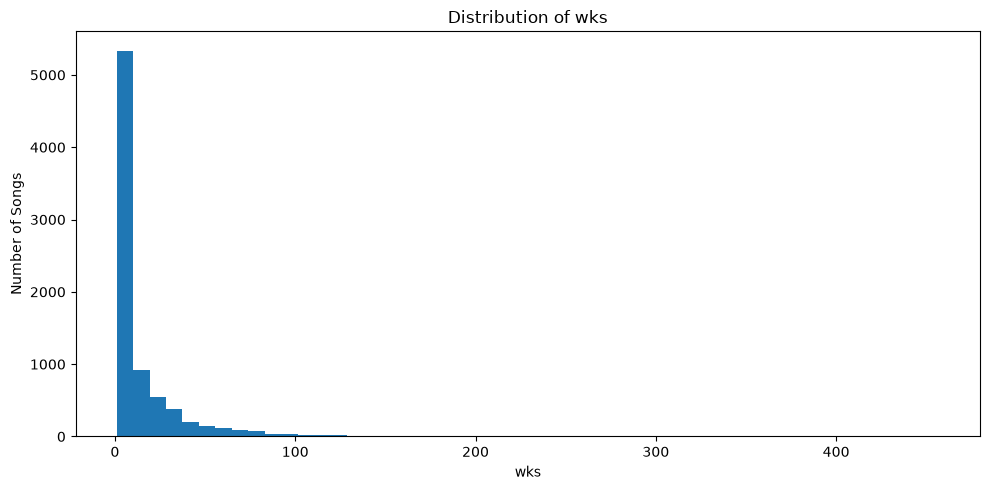

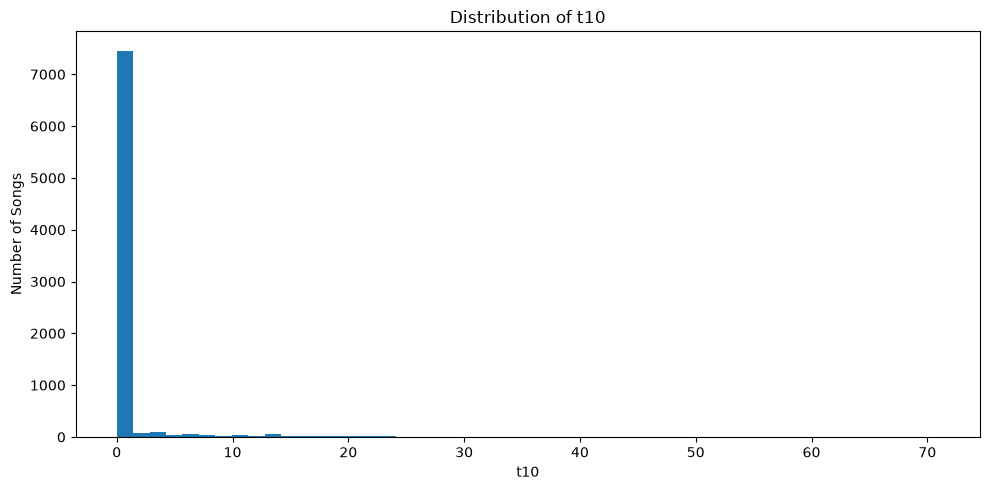

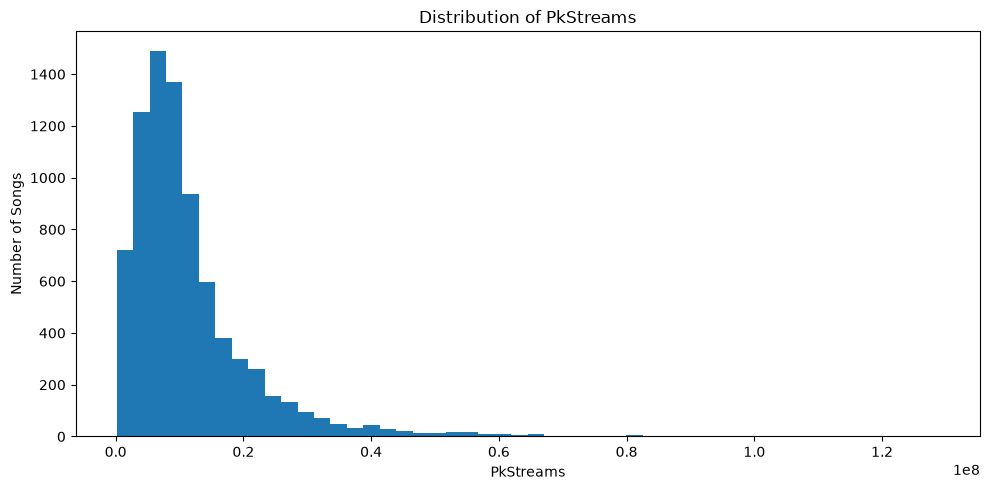

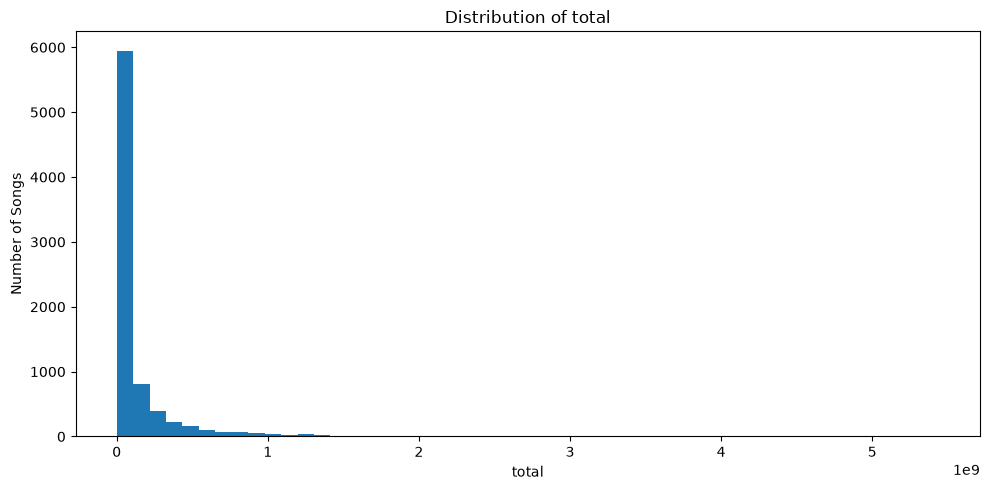

In [ ]:
# Visualize the distributions - Because the variables are heavily skewed, histograms are useful.

import matplotlib.pyplot as plt 

for col in outlier_cols:
    plt.figure(figsize=(10, 5))

    plt.hist(
        df_clean[col].dropna(),
        bins=50
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Number of Songs")


    plt.tight_layout()
    plt.show()

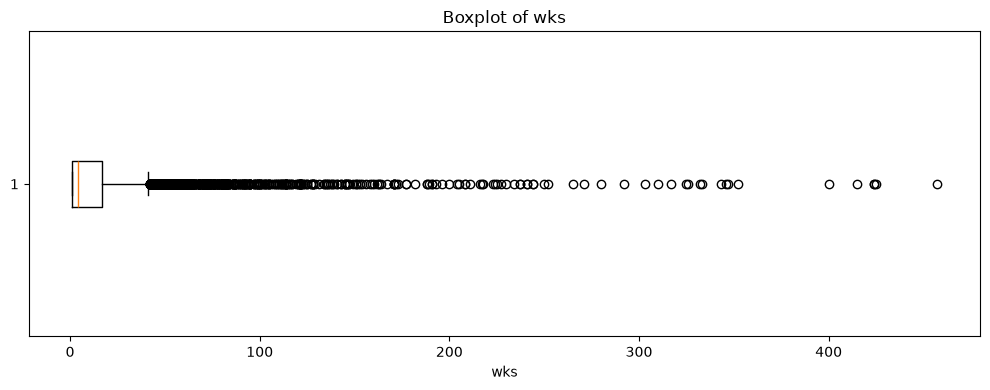

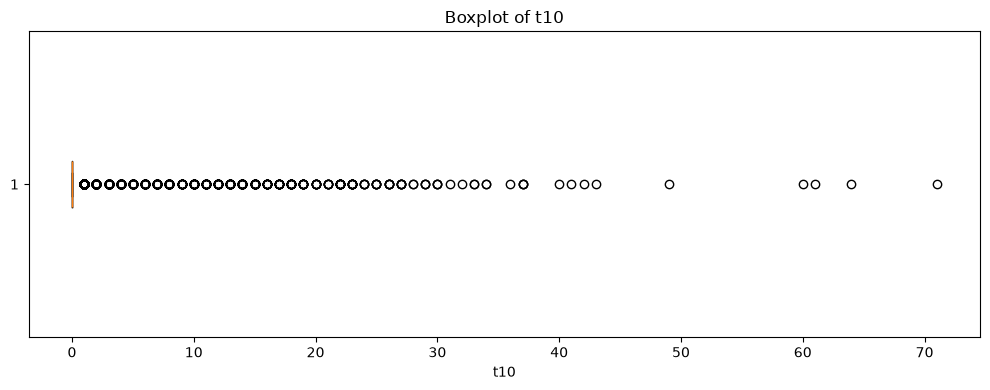

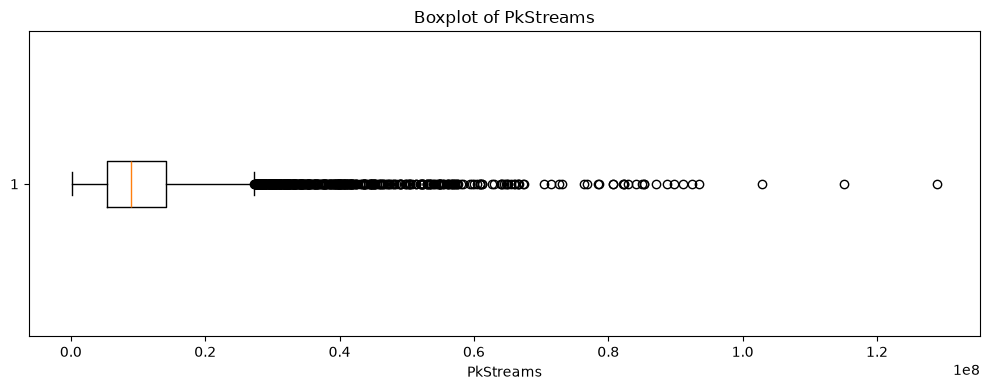

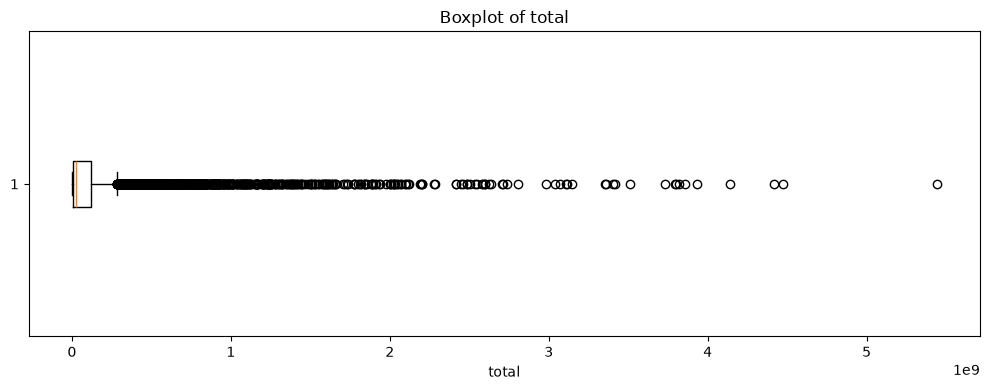

In [ ]:
# Use boxplots to visualize outliers 

for col in outlier_cols:
    plt.figure(figsize=(10, 4))

    plt.boxplot(
        df_clean[col].dropna(),
        vert=False 
    )

    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)

    plt.tight_layout()
    plt.show()

The points beyond the upper whisker are potential IQR outliers. 

Potential statistical outlier ≠ invalid observation.

In [ ]:
# Compare original and log-transformed distributions

# the total, wks, and PkStreams variables are highly right-skewed.

# We can create log-transformed analytical features

import numpy as np 

df_clean["log_total"] = np.log1p(
    df_clean["total"]
)

df_clean["log_wks"] = np.log1p(
    df_clean["wks"]
)

df_clean["log_PkStreams"] = np.log1p(
    df_clean["PkStreams"]
)

df_clean["log_t10"] = np.log1p(
    df_clean["t10"]
)



log1p(x) = log(1+x)

It safely handles zero, This is important because t10 now contains many zeros.

np.log(0) is undefined but np.log1p(0) equals 0 

In [ ]:
# Check Skewness after log transformation

log_cols = [
    "log_wks",
    "log_t10",
    "log_PkStreams",
    "log_total"
]

log_skewness = (
    df_clean[log_cols]
    .skew()
    .sort_values(ascending=False)
)

log_skewness

log_t10          3.64
log_wks          0.69
log_total        0.22
log_PkStreams   -0.66
dtype: float64

log scale provides a more balanced representation for certain statistical and ML techniques.

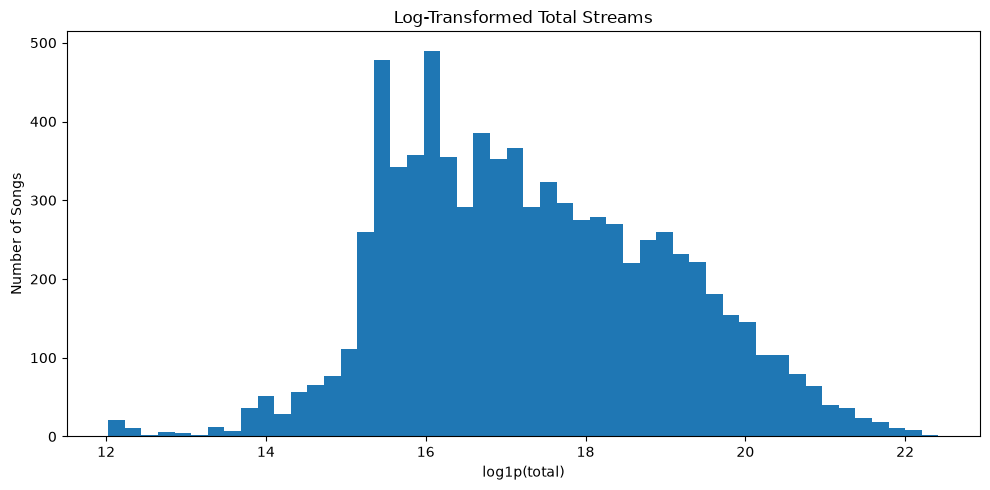

In [ ]:
# Visualize log-transformed total

plt.figure(figsize=(10, 5))

plt.hist(
    df_clean["log_total"],
    bins=50
)

plt.title("Log-Transformed Total Streams")
plt.xlabel("log1p(total)")
plt.ylabel("Number of Songs")

plt.tight_layout()
plt.show()

For the project, extreme chart-performance values are potentially meningful Capping 5.44 billion to some arbitrary threshold could remove 
precisely the information we're interested in studying.

Instead, we will retain

Original variable - for descriptive analysis
Log variable - for selected modeling / analysis
Outlier flag - for identifying extreme observations

In [ ]:
# Create a combined extreme-performance flag 
# We can identify songs that are extreme across multiple dimensions.

df_clean["extreme_performance_count"] = (
    df_clean[
        [
            "wks_outlier",
            "t10_outlier",
            "PkStreams_outlier",
            "total_outlier"
        ]
    ]
    .sum(axis=1)
)

In [ ]:
df_clean[
    "extreme_performance_count"
].value_counts().sort_index()

extreme_performance_count
0    6636
1     432
2     499
3     261
4     230
Name: count, dtype: int64

Interpretation

0 - not an IQR upper-tail outlier
1 - extreme on one metric
2 - extreme on two metrics
3 - extreme on three metrics
4 - extreme across all four metrics

This is useful for later hit-intelligence analysis.

But remember: this is an analytical flag, not a "good/bad" classification

In [ ]:
# Identify multi-dimensional extreme songs

multi_extreme = df_clean[
    df_clean["extreme_performance_count"] >= 3
].sort_values(
    "extreme_performance_count",
    ascending=False
)

multi_extreme[
    [
        "artist name",
        "song name",
        "wks",
        "t10",
        "pk",
        "PkStreams",
        "total",
        "extreme_performance_count"
    ]
].head(30)

,artist name,song name,wks,t10,pk,PkStreams,total,extreme_performance_count
809,Kendrick Lamar,DNA.,46,2,3,30933703,357502939,4
46,Billie Eilish,WILDFLOWER,114,2,9,34383970,2119232242,4
39,SZA,Kill Bill,121,26,1,55234610,2413447813,4
38,The Chainsmokers,Closer,271,28,1,46300740,2416616961,4
36,Miley Cyrus,Flowers,115,25,1,115156896,2459389429,4
35,Jimin,Who,105,27,1,64762611,2482732087,4
34,ROSÉ,APT.,92,36,1,87041494,2484667419,4
33,Teddy Swims,Lose Control,141,9,5,33398917,2507160375,4
32,Tones And I,Dance Monkey,151,41,1,52055226,2538070349,4
28,The Chainsmokers,Something Just Like This,303,12,2,33173199,2600142113,4


This can become an interesting later analysis:

Which songs simultaneously demonstrate high chart longevity, Top-10 persistence, peak streaming performance and cumulative streaming performance?

Again, that's descriptive - not a quality judgement about the songs.

20. Final outlier-treatment decision

Feature                     Outlier treatment

wks                         Retain

t10                         Retain

PkStreams                   Retain

total                       Retain

pk                          No IQR removal

peak_duration               Retain valid values

Extreme values              Flag, don't delete

Highly skewed variables     Create log versions

The principle is

An observation should only be removed when there is evidence that it is erroneous, not merely it is statistically extreme.



### Outlier Analysis and Treatment

Outlier analysis was performed using IQR-based thresholds, percentile analysis, distribution statistics, histograms and boxplots.

The variables 'wks', 't10', 'PkStreams' and 'total' exhibit right-skewed distributions with legitimate extreme observations.

Because the dataset represents global chart performance, extremely high values can correspond to genuine songs with exceptional longevity
or streaming performance. Therefore, statistical outliers were not automatically treated as data errors.

Instead:

- IQR-based upper-tail outlier flags were created.
- Extreme observations were inspected using the underlying song and artist information.
- Percentile distributions were calculated to quantify the upper tail.
- Log-transformed versions of highly skewed variables were created using 'log1p()'.
- Original values were retained for descriptive analysis.
- No observations were deleted solely because they were statistical outliers.

This approach preserves legitimate high-performance songs while providing transformed and flagged features suitable for downstream analysis and machine learning.

Preprocessing pipeline now has a clear logic

Raw Data
|
Schema Validation
|
Missing-Value Investigation
|
Artist Name Correction
|
Lyrics Availability Handling
|
t10 Structural Missingness - 0
|
x? Decoding - peak_duration
|
Numerical Consistency Validation
|
Outlier Detection
|
Outlier Flags + Log Transformations
|
Next: Text / Lyrics Cleaning

#### Text & Lyrics Quality Preprocessing 

Key Principle is never destroy the original lyrics. Create cleaned/derived columns while preserving the original lyrics, artist name and song name.

Your dataset has 8,058 songs, with 15 missing lyrics records, so we'll explicity handle those rather than dropping them.

Text & Lyrics Quality Preprocessing

We'll perform this in the following order:

Raw text
|
Identity missing / empty lyrics
|
Standardize artist/song text
|
Clean lyrics whitespace
|
Create lyrics availability flag
|
Create character & word counts
|
Check suspiciously short/long lyrics
|
Check duplicate lyrics
|
Validate text quality
|
Create NLP-ready lyrics

In [ ]:
# Inspect the current text columns - Start by checking the text fields

text_cols = [
    "artist name",
    "song name",
    "artist and title",
    "x?",
    "lyrics"
]

df_clean[text_cols].head()

,artist name,song name,artist and title,x?,lyrics
0,The Weeknd,Blinding Lights,The Weeknd - Blinding Lights,(x13),Yeah I've been tryna call I've been on my own ...
1,Ed Sheeran,Shape of You,Ed Sheeran - Shape of You,(x14),The club isn't the best place to find a lover ...
2,Harry Styles,As It Was,Harry Styles - As It Was,(x11),﻿ As It Was - Harry Styles Come on Harry we wa...
3,The Neighbourhood,Sweater Weather,The Neighbourhood - Sweater Weather,NaN,And all I am is a man I want the world in my h...
4,Lewis Capaldi,Someone You Loved,Lewis Capaldi - Someone You Loved,NaN,I'm going under and this time I fear there's n...


In [ ]:
# Then

print(df_clean[text_cols].dtypes)

artist name         str
song name           str
artist and title    str
x?                  str
lyrics              str
dtype: object


Before cleaning text, we need to know what we're actually working with.

The dataset contains:

1) artist name
2) song name
3) artist and title
4) x?
5) lyrics

However, they don't all have the same analytical purpose.

For example:

1) artist name - categorical/artist analysis
2) song name - song identification
3) artist and title - source identifier
4) x? - already handled as a structural field
5) lyrics - NLP



In [ ]:
# Preserve the original lyrics
# Before making any transformation, create an explicit original-copy column

df_clean["lyrics_original"] = df_clean["lyrics"]

lyrics_original
|
source text preserved
|
lyrics
|
can be cleaned
|
lyrics_clean
|
NLP-ready representation

This is good data-engineering practice because you can always go back to the original text.

In [ ]:
# Standardize missing lyrics
# Earlier we identified exactly 15 missing lyrics records.

# We'll represent missing lyrics as an empty string for text-processing purposes.

df_clean["lyrics"] = (
    df_clean["lyrics"]
    .fillna("")
    .astype("string")
)

In [ ]:
# Remove leading/trailing whitespace

df_clean["lyrics"] = (
    df_clean["lyrics"]
    .str.strip()
)

In [ ]:
# Check

print(
    "Empty lyrics:",
    df_clean["lyrics"].eq("").sum()
)

Empty lyrics: 15


Why convert Nan - ""?

Text-processing functions work more reliably with strings.

But we don't want to pretend those songs have lyrics.

That's why we'll create an explicit availability flag next.

In [ ]:
# Step 4- Create lyrics_available

df_clean["lyrics_available"] = (
    df_clean["lyrics"].str.len() > 0
)

In [ ]:
# Check

df_clean["lyrics_available"].value_counts()

lyrics_available
True     8043
False      15
Name: count, dtype: int64

In [ ]:
# Calculate percentage

print(
    df_clean["lyrics_available"]
    .value_counts(normalize=True)
    .mul(100)
)

lyrics_available
True    99.81
False    0.19
Name: proportion, dtype: float64


This helps us distinguish: lyrics_available = True from lyrics_available = False
without deleting the underlying chart records.

For example, all 8,058 songs can still participate in chart-performance analysis, while only the 8,043 songs with lyrics participate in NLP analysis.

In [ ]:
# Step 5 - Check missing artist and song names again

# Even though we previously fixed the two missing artist names, it is good practice to validate the text columns after preprocessing

for col in ["artist name", "song name"]:
    print(
        col,
        "missing",
        df_clean[col].isna().sum()
    )

artist name missing 2
song name missing 0


In [ ]:
# Check empty strings

for col in ["artist name", "song name"]:
    print(
        col,
        "empty:",
        df_clean[col]
        .astype("string")
        .str.strip()
        .eq("")
        .sum()
    )

artist name empty: 0
song name empty: 0


NaN and "" are different problems 

A field could be NaN or: "" or: " "

All three should be considered missing for text-quality purposes.

In [ ]:
# Step 6 - Clean artist names - We don't want aggressive normalization yet.

# For example, we should not automicatically convert: ROSE to: rose
# because accents and capitalization can contain useful identity information.
# Instead, perform conservative whitespace cleaning.

for col in ["artist name", "song name"]:
    df_clean[col] = (
        df_clean[col]
        .astype("string")
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
    )

What does this do?

"   Taylor  Swift  "

becomes "Taylor Swift"

But "ROSE" remains "ROSE" 

This preserves the original semantic content.

In [ ]:
# Step 7 - Create a clean lyrics column - rather than overwriting lyrics, create:

df_clean["lyrics_clean"] = df_clean["lyrics"]

In [ ]:
# Now normalize whitespace

df_clean["lyrics_clean"] = (
    df_clean["lyrics_clean"]
    .str.replace(r"\r\n?", "\n", regex=True)
    .str.replace(r"[ \t]+", " ", regex=True)
    .str.replace(f"\n{3,}", "\n\n", regex=True)
    .str.strip()
)

Lyrics often contain inconsistent formatting:

Verse 1

I love you 

I love you 

We don't necessarily want to remove line structure completely. Instead, we normalize excessive whitespace while preserving meaningful line breaks.

In [ ]:
# Step 8 - Check whether cleaning changed the lyrics

lyrics_changed = (
    df_clean["lyrics_original"].fillna("").astype("string")
    != df_clean["lyrics_clean"]
)

print(
    "Lyrics changed:",
    lyrics_changed.sum()
)

print(
    "Lyrics unchanged:",
    (~lyrics_changed).sum()
)

Lyrics changed: 0
Lyrics unchanged: 8043


This tells us how much of the dataset was affected by our cleaning operation.

We're not blindly transforming everything.

In [ ]:
# Step 9: Create character count

df_clean["lyrics_char_count"] = (
    df_clean["lyrics_clean"]
    .str.len()
)

In [ ]:
# Inspect

df_clean["lyrics_char_count"].describe()

count    8,043.00
mean     2,038.09
std      1,195.19
min         33.00
25%      1,399.50
50%      1,858.00
75%      2,457.50
max     65,511.00
Name: lyrics_char_count, dtype: float64

We previously found approximately:

Mean - 2,034 characters
Median - 1,857
Maximum - 65,511

This gives us an initial understanding of lyric length.

In [ ]:
# Step 10 - Create word count

df_clean["lyrics_word_count"] = (
    df_clean["lyrics_clean"]
    .str.split()
    .str.len()
)

But empty lyrics will produce a count of zero, which is exactly what we want for NLP preparation.


In [ ]:
df_clean["lyrics_word_count"].describe()

count    8,043.00
mean       403.98
std        231.88
min          7.00
25%        280.00
50%        370.00
75%        487.00
max     12,518.00
Name: lyrics_word_count, dtype: float64

previously found 

Mean = 403 words, Median = 370 and Maximum = 12,518 

In [ ]:
# Step 11 - Create line count - Lyrics have useful structural information

df_clean["lyrics_line_count"] = (
    df_clean["lyrics_clean"]
    .str.split("\n")
    .str.len()
)

In [ ]:
# Check

df_clean["lyrics_line_count"].describe()

count   8,043.00
mean        1.00
std         0.00
min         1.00
25%         1.00
50%         1.00
75%         1.00
max         1.00
Name: lyrics_line_count, dtype: float64

Later we can investigate whether lyric structure relates to:

Chart longevity, streaming performance, genre proxies and artist characteristics

This is feature engineering rather than simply cleaning.

In [ ]:
# Step 12 - Calculate average words per line - This gives us another useful lyric-structure feature.

df_clean["words_per_line"] = (
    df_clean["lyrics_word_count"] /
    df_clean["lyrics_line_count"].replace(0, np.nan)
)

In [ ]:
# Check

df_clean["words_per_line"].describe()

count    8,043.00
mean       403.98
std        231.88
min          7.00
25%        280.00
50%        370.00
75%        487.00
max     12,518.00
Name: words_per_line, dtype: float64

Why replace zero?

we don't want: words / 0
For songs without lyrics, this should remain missing rather than artificially becoming zero.

In [ ]:
# Step 13 - Check empty or extremely short lyrics 

short_lyrics = df_clean[
    df_clean["lyrics_available"] &
    (df_clean["lyrics_word_count"] < 10)
]

print(
    "Lyrics with fewer than 10 words:",
    len(short_lyrics)
)

Lyrics with fewer than 10 words: 4


In [ ]:
# Inspect

short_lyrics[
    [
        "artist name",
        "song name",
        "lyrics_word_count",
        "lyrics_clean"
    ]
].head(20)

,artist name,song name,lyrics_word_count,lyrics_clean
5376,Martin Garrix,Animals,8.00,We're the fuckin' animals We're the fuckin' an...
6693,Kid Cudi,Beautiful Trip,7.00,"Oh, oh Oh Three (three, two, one)"
6914,Martin Garrix,Animals,8.00,We're the fuckin' animals We're the fuckin' an...
7445,Metro Boomin,Borrowed Love,8.00,After laughter comes tears After laughter come...


Don't automatically delete short lyrics.

A song can legitimately have:

1) Repeated vocal phrases.
2) an intro
3) an interlude
4) instrumental sections
5) a short spoken sample

We're identifying them for investigation.

In [ ]:
# Step 14 - Check extremely long lyrics
# We previously saw a maximum of around 12,518 records

long_lyrics = df_clean[
    df_clean["lyrics_available"]
].sort_values(
    "lyrics_word_count",
    ascending=False
)

long_lyrics[
    [
        "artist name",
        "song name",
        "lyrics_word_count",
        "lyrics_char_count"
    ]
].head(20)

,artist name,song name,lyrics_word_count,lyrics_char_count
5637,Metro Boomin,I Can't Save You [with Future & feat. Don Toli...,"12,518.00","65,511.00"
7923,Ken Floor,Happy,"2,844.00","13,482.00"
5802,Ravyn Lenae,O Holy Night,"2,354.00","12,592.00"
7871,Kendrick Lamar,Mortal Man,"2,132.00","11,086.00"
6743,Kanye West,Jesus Lord pt 2,"1,985.00","10,310.00"
762,Metro Boomin,Superhero [with Future & Chris Brown],"1,891.00","9,665.00"
3066,Drake,Family Matters,"1,689.00","8,592.00"
6649,"Tyler, The Creator",WILSHIRE,"1,677.00","8,377.00"
1635,MC PH,Let's Go 4,"1,601.00","8,279.00"
2808,Lil Uzi Vert,New Patek,"1,544.00","7,572.00"


Extremely long lyrics could represent:

1) genuine long-form lyrics
2) spoken-word sections
3) lyrics containing metadata
4) repeated lyrics
5) scraped website content
6) formatting artifacts

Again, investigate before deleting

In [ ]:
# Inspect the longest lyric

longest_song = long_lyrics.iloc[0]

print("Artist:", longest_song["artist name"])
print("Song:", longest_song["song name"])
print("Word count:", longest_song["lyrics_word_count"])
print("Character count:", longest_song["lyrics_char_count"])

print("\nLyrics preview:\n")
print(longest_song["lyrics_clean"][:3000])

Artist: Metro Boomin
Song: I Can't Save You [with Future & feat. Don Toliver]
Word count: 12518.0
Character count: 65511.0

Lyrics preview:

now that ive spent hours on this i have no motivation to update it so this is all you get im actually done with this one so if i stop liking anything i probably wont remove it theres a sequel tho !!1! # 03' Adolescence - J. Cole 100 Degrees - Rich Brian 10:37 - Beach House 10 Mile Stereo - Beach House 11:23 - m j apanay 1, 2 - mxmtoon 1.5 - 21 Savage feat. Offset 151 Rum - JID 17again - Powfu 18 Months - THEY. feat. Ty Dolla $ign 1999 - beabadoobee 1999 - Big K.R.I.T. feat. Lloyd 1999 - Bedroom Session - beabadoo bee 1Train - A$AP Rocky feat. Kendrick Lamar, Joey Bada$$, Yelawolf, Danny Brown, Action Bronson, & Big K.R.I.T.⠀ 2:00 AM - ReptileLegit 2020 - EDEN 2020 - Kojey Radical 20 Wave Caps - Earl Sweatshirt feat. Domo Genesis 21 Questions - 50 Cent feat. Nate Dogg 22 Two's - JAY-Z 24 - IDK 24/7 - The Neighbourhood 24's (Vocals Only) - T.I.⠀ 27 

This is manual data-quality inspection

A word count of 12,518 doesn't automatically mean the data is wrong.

the actual text tells us whether it's 

legitimate lyrics or:
scraped/duplicated/contaminated text


In [ ]:
# Step 16 - Check duplicate lyrics
# Earlier we found the lyrics column has 7,783 unique values.

# Let's identify repeated lyrics

duplicate_lyrics = (
    df_clean[
        df_clean["lyrics_available"]
    ]
    .groupby("lyrics_clean")
    .agg(
        song_count=("song name", "count"),
        artists=("artist name", "nunique")
    )
    .sort_values(
        "song_count",
        ascending=False
    )
)


duplicate_lyrics.head()

,song_count,artists
lyrics_clean,,
"Yeah, I'm gonna take my horse to the old town road I'm gonna ride 'til I can't no more I'm gonna take my horse to the old town road I'm gonna ride (Kio, Kio) 'til I can't no more I got the horses in the back Horse tack is attached Hat is matte black Got the boots that's black to match Riding on a horse, ha You can whip your Porsche I been in the valley You ain't been up off the porch, now Can't nobody tell me nothing You can't tell me nothing Can't nobody tell me nothing You can't tell me nothing Riding on a tractor Lean all in my bladder Cheated on my baby You can go and ask her My life is a movie Bull riding and boobies Cowboy hat from Gucci Wrangler on my booty Can't nobody tell me nothing You can't tell me nothing Can't nobody tell me nothing You can't tell me nothing Yeah, I'm gonna take my horse to the old town road I'm gonna ride 'til I can't no more I'm gonna take my horse to the old town road I'm gonna ride 'til I can't no more Hat down, cross-town, livin' like a rockstar Spent a lot of money on my brand-new guitar Baby's got a habit: diamond rings and Fendi sports bras Ridin' down Rodeo in my Maserati sports car Got no stress, I've been through all that I'm like a Marlboro Man so I kick on back Wish I could roll on back to that old town road I wanna ride 'til I can't no more Yeah, I'm gonna take my horse to the old town road I'm gonna ride 'til I can't no more I'm gonna take my horse to the old town road I'm gonna ride 'til I can't no more",4,1
I'm dreaming of a white Christmas Just like the ones I used to know Where the treetops glisten And children listen To hear sleigh bells in the snow I'm dreaming of a white Christmas With every Christmas card I write May your days be merry and bright And may all your Christmases be white I'm dreaming of a white Christmas Just like the ones I used to know Where the treetops glisten And children listen To hear sleigh bells in the snow I'm dreaming of a white Christmas With every Christmas card I write May your days be merry and bright And may all your Christmases be white,3,1
"I'm driving home for Christmas Oh, I can't wait to see those faces I'm driving home for Christmas, yeah Well, I'm moving down that line And it's been so long But I will be there I sing this song To pass the time away Driving in my car Driving home for Christmas It's gonna take some time, but I'll get there Top to toe in tailbacks Oh, I got red lights all around But soon there'll be a freeway, yeah Get my feet on holy ground So I sing for you Though you can't hear me When I get through And feel you near me Driving in my car I'm driving home for Christmas Driving home for Christmas With a thousand memories I take a look at the driver next to me He's just the same Just the same Top to toe in tailbacks Oh, I got red lights all around I'm driving home for Christmas, yeah Get my feet on holy ground So I sing for you Though you can't hear me When I get through Oh and feel you near me Driving in my car Driving home for Christmas Driving home for Christmas With a thousand memories I take look at the driver next to me He's just the same He's driving home, driving home",3,1
"I'm findin' ways to articulate the feeling I'm goin' through I just can't say I don't love you 'Cause I love you, yeah It's hard for me to communicate the thoughts that I hold But tonight, I'm gon' let you know Let me tell the truth Baby, let me tell the truth, yeah You know what I'm thinkin', see it in your eyes You hate that you want me, hate it when you cry You're scared to be lonely, especially in the night I'm scared that I'll miss you, happens every time I don't want this feelin', I can't afford love I try to find a reason to pull us apart It ain't workin' 'cause you're perfect And I know that you're worth it I can't walk away, (oh) Even though we're going through it And it makes you feel alone Just know that I would die for you Baby, I would die for you, yeah The distance and the time between us It'll nev

Repeated lyrics can be legitimate.

For example:

1) the same song may occur more than once.
2) instrumental tracks may have no lyrics.
3) seasonal songs can be source text
4) multiple versions can use the same lyrics.

So duplicate lyrics do not mean duplicate records.

In [ ]:
# Step 17 - Find the songs sharing duplicate lyrics

duplicate_lyrics_values = (
    duplicate_lyrics[
        duplicate_lyrics["song_count"] > 1
    ]
    .index 
)


duplicate_lyrics_records = df_clean[
    df_clean["lyrics_clean"].isin(
        duplicate_lyrics_values
    )
][
    [
        "artist name",
        "song name",
        "wks",
        "pk",
        "total",
        "lyrics_word_count"
    ]
].sort_values("lyrics_word_count")

duplicate_lyrics_records.head(30)

,artist name,song name,wks,pk,total,lyrics_word_count
6914,Martin Garrix,Animals,5,41,5478432,8.00
5376,Martin Garrix,Animals,6,17,12303018,8.00
4475,Ariana Grande,intro,2,72,21389867,41.00
1225,Ariana Grande,intro,17,25,232026615,41.00
783,Elvis Presley,Blue Christmas,44,34,367152162,86.00
7900,Elvis Presley,Blue Christmas,1,141,1391837,86.00
2820,Martin Solveig,Intoxicated,27,60,63730970,90.00
6588,Martin Solveig,Intoxicated,6,109,6521392,90.00
7980,David Guetta,Hey Mama,1,194,938172,98.00
1187,David Guetta,Hey Mama,48,3,241200778,98.00


In [ ]:
# Step 18 - Check repeated words / sections.
# We don't want to perform aggressive NLP cleaning in the notebook, but we can identify obvious formatting problems.

html_like = df_clean[
    df_clean["lyrics_clean"]
    .str.contains(
        r"<[^>]+>",
        regex=True,
        na=False
    )
]

print(
    "Lyrics containing HTML-like tags:",
    len(html_like)
)

Lyrics containing HTML-like tags: 0


In [ ]:
html_like[
    [
        "artist name",
        "song name",
        "lyrics_clean"
    ]
].head(10)

,artist name,song name,lyrics_clean


In [ ]:
# Step 19 - Check URL Contamination

url_like = df_clean[
    df_clean["lyrics_clean"]
    .str.contains(
        r"http?://|www|.",
        regex=True,
        case=False,
        na=False
    )
]

print(
    "Lyrics containing URLs:",
    len(url_like)
)

Lyrics containing URLs: 8043


Lyrics scraped from websites can sometimes contain:
http://...
www....

which would contaminate sentiment, topic modeling, word frequencies and other NLP analyses.

If these exist, we can handle them later

In [ ]:
# Step 20 - Check unusual metadata contamination - Look for common bracketed metadata:

metadata_patterns = [
    r"\[verse\]",
    r"\[chorus\]",
    r"\[intro\]",
    r"\[outro\]",
    r"\[bridge\]",
    f"\[lyrics\]"
]

for pattern in metadata_patterns:
    count = df_clean["lyrics_clean"].str.contains(
        pattern,
        regex=True,
        case=False,
        na=False
    ).sum()


print(f"{pattern}: {count}")

\[lyrics\]: 0


Don't necessarily remove [Verse], [Chorus], etc

Those labels could actually be useful features later.

For example:

number of verses, number of choruses, number of bridges

So for now we've detecting, not deleting.

In [ ]:
# Step 21 - Create a lyrics quality summary - Now create a compact quality report:

lyrics_quality = pd.DataFrame({
    "Metric": [
        "Total records",
        "Lyrics available",
        "Lyrics missing",
        "Lyrics available %",
        "Mean word count",
        "Median word count",
        "Maximum word count",
        "Mean character count",
        "Median character count",
        "Maimum character count"
    ],
    "Value": [
        len(df_clean),
        df_clean["lyrics_available"].sum(),
        (~df_clean["lyrics_available"]).sum(),
        df_clean["lyrics_available"].mean() * 100,
        df_clean.loc[
            df_clean["lyrics_available"],
            "lyrics_word_count"
        ].mean(),
        df_clean.loc[
            df_clean["lyrics_available"],
            "lyrics_word_count"
        ].median(),
        df_clean["lyrics_word_count"].max(),
        df_clean.loc[
            df_clean["lyrics_available"],
            "lyrics_char_count"
        ].mean(),
        df_clean.loc[
            df_clean["lyrics_available"],
            "lyrics_char_count"
        ].median(),
        df_clean["lyrics_char_count"].max()
    ]
})

lyrics_quality

,Metric,Value
0,Total records,"8,058.00"
1,Lyrics available,"8,043.00"
2,Lyrics missing,15.00
3,Lyrics available %,99.81
4,Mean word count,403.98
5,Median word count,370.00
6,Maximum word count,"12,518.00"
7,Mean character count,"2,038.09"
8,Median character count,"1,858.00"
9,Maimum character count,"65,511.00"


In [ ]:
# Step 22 - Validate the new features

feature_check = [
    "lyrics_available",
    "lyrics_char_count",
    "lyrics_word_count",
    "lyrics_line_count",
    "words_per_line"
]

df_clean[feature_check].isna().sum()

lyrics_available      0
lyrics_char_count    15
lyrics_word_count    15
lyrics_line_count    15
words_per_line       15
dtype: int64

For the missing-lyrics records, we expect:
lyrics_available - False
lyrics_char_count - 0
lyrics_word_count - 0
lyrics_line_count - 1 with the current implementation
words_per_line - 0 or NaN depending on how we handle empty strings

I recommend making lyrics_line_count explicitly zero for unavailable lyrics.


In [ ]:
df_clean.loc[
    ~df_clean["lyrics_available"],
    "lyrics_line_count"
] = 0

In [ ]:
df_clean.loc[
    ~df_clean["lyrics_available"],
    "words_per_line"
] = np.nan

This gives a cleaner semantic interpretation.

In [ ]:
# Step 23 - final text-feature validation

print("Total records:", len(df_clean))

print(
    "Lyrics available:",
    df_clean["lyrics_available"].sum()
)

print(
    "Lyrics unavailable",
    (~df_clean["lyrics_available"]).sum()
)

print(
    "Empty cleaned lyrics:",
    df_clean["lyrics_clean"].eq("").sum()
)

print(
    "Negative word counts:",
    (df_clean["lyrics_word_count"] < 0).sum()
)

print(
    "Negative character counts:",
    (df_clean["lyrics_char_count"] < 0).sum()
)

Total records: 8058
Lyrics available: 8043
Lyrics unavailable 15
Empty cleaned lyrics: 0
Negative word counts: 0
Negative character counts: 0


Step 24 - Don't lowercase the main lyrics column yet 

You might see tutorials doing 

lyrics.lower()

Don't overwrite lyrics_clean with lowercase text yet.

For NLP, we'll eventually create something like

lyrics_clean
|
lyrics_nlp
|
lowercase
|
tokenization
|
stopword handling
|
lemmatization

Different NLP techniques require different preprocessing

For example, capitalization may matter for:

named entities, artist names and stylistic analysis 

So keep the relatively clean text intact.

### Text and Lyrics Quality Preprocessing

Text fields were processed conservatively to preserve the original information.

### Lyrics handling

- Original lyrics were preserved in `lyrics_original`.
- Missing lyrics were converted to empty strings for processing.
- A `lyrics_available` flag was created
- Excessive whitespace was normalized.
- Original line breaks were retained where possible.
- Character count, word count, and line count features were created.
- `words_per_line` was calculated as a structural lyric feature.
- Very short and very long lyrics were identified for quality inspection.
- Duplicate lyric texts were investigated without automatically removing records.
- HTML-like tags, URLs and metadata patterns were checked for possible contamination.

Only the 15 records with missing lyrics are unavailable for lyric-based NLP analysis. These records remain in the dataset for chart 
performance analysis.

The original lyrics were preserved to ensure traceability and allow task-specific NLP preprocessing later.

The goal is to determine whether the artist/song text fields are internally consistent, and whether repeated artist-song combinations represent genuine duplicate records or legitimate repeated observations.

We will not delete anything automatically.

Categorical/Text Consistency & Duplicate Investigation

We'll follow this sequence:

1. Check missing/empty categorical fields.

2. Check whitespace inconsistencies

3. Check artist-name consistency

4. Check song-name consistency

5. Compare "artist and title" with separate fields

6. Investigate duplicate artist-song combinations

7. Distinguish exact duplicates from legitimate duplicates

8. Create duplicate flags

9. Decide what should/shouldn't be removed

In [ ]:
# Define the categorical/text columns 

categorical_cols = [
    "artist name",
    "song name",
    "artist and title"
]

print(categorical_cols)

['artist name', 'song name', 'artist and title']


These are the fields we will investigate.

We won't include lyrics here because lyric similarity is a separate NLP/data-quality issue.

In [ ]:
# Check missing values

categorical_missing = df_clean[
    categorical_cols
].isna().sum()

categorical_missing

artist name         2
song name           0
artist and title    0
dtype: int64

In [ ]:
# Inspect the two records again

missing_artist = df_clean[
    df_clean["artist name"].isna()
]

missing_artist[
    [
        "artist name",
        "song name",
        "artist and title"
    ]
]

,artist name,song name,artist and title
4283,<NA>,Various Artists -,Various Artists -
5647,<NA>,Dj Ozuna -,Dj Ozuna -


In [ ]:
# Fill the two artist names - Use explicit assignment

df_clean.loc[
    df_clean["artist and title"].eq("Various Artists -"),
    "artist name"
] = "Various Artists"

df_clean.loc[
    df_clean["artist and title"].eq("Dj Ozuna -"),
    "artist name"
] = "Dj Ozuna"

We're not guessing from statistics or imputing an artist.
The source's artist and title field directly provides the artist portion:

Various Artists - 
|
Various Artists
|
Dj Ozuna
|
Dj Ozuna

This is therefore a deterministic correction.

In [ ]:
# Step 3 - Verify Immediately

print(
    "Missing artist names:",
    df_clean["artist name"].isna().sum()
)

Missing artist names: 0


In [ ]:
# Also check empty strings

print(
    "Empty artist names:",
    df_clean["artist name"]
    .astype("string")
    .str.strip()
    .eq("")
    .sum()
)

Empty artist names: 0


In [ ]:
# Verify the actual records

df_clean[
    df_clean["artist and title"].isin(
        ["Various Artists -", "Dj Ozuna -"]
    )
][
    [
        "artist name",
        "song name",
        "artist and title"
    ]
]

,artist name,song name,artist and title
4283,Various Artists,Various Artists -,Various Artists -
5647,Dj Ozuna,Dj Ozuna -,Dj Ozuna -


In [ ]:
# Step 5 - Rerun the categorical missing-value check 

categorical_cols = [
    "artist name",
    "song name",
    "artist and title"
]

categorical_missing = (
    df_clean[categorical_cols]
    .isna()
    .sum()
)


categorical_missing

artist name         0
song name           0
artist and title    0
dtype: int64

In [ ]:
# Check empty values

for col in categorical_cols:
    empty_count = (
        df_clean[col]
        .astype("string")
        .str.strip()
        .eq("")
        .sum()
    )


print(f"{col}: {empty_count} empty values")

artist and title: 0 empty values


In [ ]:
# Step 3 - Check Empty strings - Missing values aren't represented as NaN.

# A text field can contain "", "   "

for col in categorical_cols:
    empty_count = (
        df_clean[col]
        .astype("string")
        .str.strip()
        .eq("")
        .sum()
    )


    print(f"{col}: {empty_count} empty values")

artist name: 0 empty values
song name: 0 empty values
artist and title: 0 empty values


This catches hidden missing values that isna() won't detect.

In [ ]:
# Check leading/trailing whitespace - Let's identify records that contain unnecessary whitespace.

for col in categorical_cols:
    whitespace_mask = (
        df_clean[col].astype("string")
        != df_clean[col].astype("string").str.strip()
    )


    print(
        f"{col}: {whitespace_mask.sum()} "
        "records with leading/trailing whitespace"
    )

artist name: 0 records with leading/trailing whitespace
song name: 0 records with leading/trailing whitespace
artist and title: 0 records with leading/trailing whitespace


In [ ]:
# If there are records, inpsect them:

whitespace_records = df_clean[
    (
        df_clean["artist name"].astype("string")
        != df_clean["artist name"].astype("string").str.strip()
    )
    |
    (
        df_clean["song name"].astype("string")
        != df_clean["song name"].astype("string").str.strip()
    )
]

whitespace_records[
    ["artist name","song name"]
].head(20)

,artist name,song name


In [ ]:
# 5. Standardize Whitespace - We already did this for artist/song names, but this is a good place to formally apply it.

for col in ["artist name", "song name"]:
    df_clean[col] = (
        df_clean[col]
        .astype("string")
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
    )

Why only whitespace ? We don't want aggressive normalization such as: .str.lower( ) because artist and song names can contain meaningful 
capitalization and Unicode characters.

For example ROSE, BTS, J.Cole, HUNTR/X shouldn't be unnecessarily altered.


In [ ]:
# 6. Check case inconsistencies

# Now we can investigate whether the same artist appears with different capitalization.

# Create a temporary normalized version.

artist_case_check = (
    df_clean["artist name"]
    .astype("string")
    .str.strip()
    .str.casefold()
)

In [ ]:
# Now find the normalized names associated with multiple original forms:

artist_case_variations = (
    pd.DataFrame({
        "original_artist": df_clean["artist name"],
        "normalized_artist": artist_case_check
    })
    .groupby("normalized_artist")["original_artist"]
    .nunique()
    .sort_values(ascending=False)
    )

artist_case_variations.head(20)

normalized_artist
jimin                  2
young miko             1
ñengo flow             1
zedd                   1
zeynep bastık          1
zhu                    1
zico                   1
zion & lennox          1
ziv zaifman            1
zoe wees               1
zuna                   1
zxkai                  1
zzoilo                 1
zé felipe              1
zé neto & cristiano    1
¥$                     1
íñigo quintero         1
zayn                   1
6lack                  1
99 souls               1
Name: original_artist, dtype: int64

Suppose the dataset contains:

Taylor Swift
TAYLOR SWIFT
taylor swift

These may be the same artist represented inconsistently.

We need to identify such cases before deciding whether normalization is appropriate.

In [ ]:
# Display actual artist variations - Let's inspect the cases where multiple representations exist.

artist_variation_table = (
    pd.DataFrame({
        "original_artist": df_clean["artist name"],
        "normalized_artist": artist_case_check
    })
    .groupby("normalized_artist")["original_artist"]
    .agg(
        unique_forms=lambda x: sorted(x.unique()),
        form_count="nunique"
    )
    .query("form_count > 1")
    .sort_values("form_count", ascending=False)
)

artist_variation_table.head(30)

,unique_forms,form_count
normalized_artist,,
jimin,['JIMIN' 'Jimin'],2


Don't automatically merge 

For example, two differently written artist names might actually represent:

Different artists, collaborations, aliases and formatting differences 

We inspect before standardizing.

In [ ]:
# Do the same for song names

song_case_check = (
    df_clean["song name"]
    .astype("string")
    .str.strip()
    .str.casefold()
)


song_variations = (
    pd.DataFrame({
        "original_song": df_clean["song name"],
        "normalized_song": song_case_check
    })
    .groupby("normalized_song")["original_song"]
    .agg(
        unique_forms=lambda x: sorted(x.unique()),
        form_count = "nunique"
    )
    .query("form_count > 1")
    .sort_values("form_count", ascending=False)
)

song_variations.head(30)

,unique_forms,form_count
normalized_song,,
deja vu,['DEJA VU' 'Deja Vu' 'Deja vu' 'deja vu'],4
blue,['BLUE' 'Blue' 'blue'],3
intro,['INTRO' 'Intro' 'intro'],3
the greatest,['THE GREATEST' 'The Greatest' 'The greatest'],3
rockstar,['ROCKSTAR' 'Rockstar' 'rockstar'],3
all eyes on you,['All Eyes On You' 'All Eyes on You'],2
4x4,['4X4' '4x4'],2
apaga el cel,['APAGA EL CEL' 'Apaga El Cel'],2
back to you,['Back To You' 'Back to You'],2


In [ ]:
# Check uniqueness of artist names

print(
    "Unique artists:",
    df_clean["artist name"].nunique()
)


print(
    "Unique artist values including missing:",
    df_clean["artist name"].nunique(dropna=False)
)

Unique artists: 1794
Unique artist values including missing: 1794


In [ ]:
# Check uniqueness of song names:

print(
    "Unique song names:",
    df_clean["song name"].nunique()
)

Unique song names: 7277


In [ ]:
# Create an artist-song key - This is extremely useful for duplicate investigation.


df_clean["artist_song_key"] = (
    df_clean["artist name"].astype("string")
    + " | "
    + df_clean["song name"].astype("string")
)

In [ ]:
# Count duplicate artist-song combinations

artist_song_counts = (
    df_clean["artist_song_key"]
    .value_counts()
)


artist_song_counts.head(20)

artist_song_key
Lil Nas X | Old Town Road        4
Ed Sheeran | Shape of You        3
The Weeknd | Die For You         3
The Weeknd | Save Your Tears     3
Dua Lipa | Levitating            3
John Legend | All of Me          3
BTS | Butter                     3
Imagine Dragons | Enemy          3
FIFTY FIFTY | Cupid              3
CKay | love nwantiti             3
Lunay | Soltera                  3
OMI | Cheerleader                3
Bing Crosby | White Christmas    3
Rauw Alejandro | Tattoo          3
Drake | Pop Style                3
Brytiago | Asesina               3
Bing Crosby | Mele Kalikimaka    3
Lorde | Homemade Dynamite        3
Taylor Swift | Bad Blood         3
The Weeknd | Blinding Lights     2
Name: count, dtype: int64[pyarrow]

In [ ]:
print(
    "Unique artist song combinations:",
    artist_song_counts.size
)

print(
        "Artist-song combinations appearing more than once:",
        (artist_song_counts > 1).sum()
)

Unique artist song combinations: 7826
Artist-song combinations appearing more than once: 212


Earlier we found 232 duplicate artist-song combinations, so this gives us a current verification.

In [ ]:
# 13. Identify all rows belonging to duplicate groups 
# This is where you previously encountered the NameError, so we'll define everything explicity

duplicate_mask = df_clean.duplicated(
    subset=["artist name", "song name"],
    keep = False
)

duplicate_artist_song = (
    df_clean.loc[duplicate_mask]
    .sort_values(
        ["artist name", "song name", "wks"]
    )
)

print(
    "Rows belonging to duplicate artist-song groups:",
    len(duplicate_artist_song)
)

Rows belonging to duplicate artist-song groups: 444


Important distinction

There are two different numbers: 232 duplicate artist-song combinations

versus

number of rows belonging to those duplicate groups

They are not necessarily the same.

There are:

2 duplicate groups
5 rows belonging to duplicate groups



In [ ]:
# Recreate peak_duration first, then recreate duplicate_artist_song

# Remove old version if it exists
if "peak_duration" in df_clean.columns:
    df_clean = df_clean.drop(columns=["peak_duration"])

# Extract xN from values such as "(x1)", "(x2)", etc.
df_clean["peak_duration"] = pd.to_numeric(
    df_clean["x?"]
        .astype("string")
        .str.extract(r"\(x(\d+)\)", expand=False),
    errors="coerce"
).astype("Int64")

#Check
print("peak_duration created successfully.")
print("Non-null:", df_clean["peak_duration"].notna().sum())
print("Missing:", df_clean["peak_duration"].isna().sum())
print(df_clean["peak_duration"].value_counts(dropna=False).head(10))

peak_duration created successfully.
Non-null: 334
Missing: 7724
peak_duration
<NA>    7724
1        147
2         55
3         38
4         26
5         13
6         10
7         10
8          8
10         6
Name: count, dtype: Int64


In [ ]:
# Recreate duplicate_artist song

duplicate_mask = df_clean.duplicated(
    subset=["artist name", "song name"],
    keep=False
)

duplicate_artist_song = (
    df_clean.loc[duplicate_mask]
    .sort_values(["artist name", "song name", "wks"])
    .copy()
)

print("Duplicate artist-song records:", len(duplicate_artist_song))
print(
    "Unique artist-song combinations:",
    duplicate_artist_song[["artist name", "song name"]]
    .drop_duplicates()
    .shape[0]
)

Duplicate artist-song records: 444
Unique artist-song combinations: 212


In [ ]:
# 14. Inspect duplicate records

duplicate_artist_song[
    [
        "artist name",
        "song name",
        "artist and title",
        "wks",
        "t10",
        "pk",
        "peak_duration",
        "PkStreams",
        "total"
    ]
].head(50)

,artist name,song name,artist and title,wks,t10,pk,peak_duration,PkStreams,total
4227,4batz,act ii: date @ 8,4batz - act ii: date @ 8,2,NaN,55,<NA>,14488042,24862884
3024,4batz,act ii: date @ 8,4batz - act ii: date @ 8,6,NaN,132,<NA>,9707311,54188571
3042,A Great Big World,Say Something,A Great Big World - Say Something,29,NaN,29,<NA>,2923728,53471527
2627,A Great Big World,Say Something,A Great Big World - Say Something,34,6.00,7,<NA>,4468700,73725928
8007,AFROJACK,SummerThing!,AFROJACK - SummerThing!,2,NaN,201,<NA>,455368,648236
5086,AFROJACK,SummerThing!,AFROJACK - SummerThing!,10,NaN,114,<NA>,1918482,15127973
4793,ANOTR,Talk To You,ANOTR - Talk To You,2,NaN,178,<NA>,9048950,17914955
2865,ANOTR,Talk To You,ANOTR - Talk To You (ft. 54 Ultra),6,NaN,66,<NA>,11575102,60953532
4847,Alesso,Heroes,Alesso - Heroes (we could be),5,NaN,48,<NA>,4093426,17405115
1504,Alesso,Heroes,Alesso - Heroes (we could be),52,NaN,11,<NA>,7138967,182118979


This is the most important manual inspection step.

We're looking for whether duplicate artist-song records have different chart-performance values.

In [ ]:
print("df_clean columns:")
print(df_clean.columns.tolist())

print("\nduplicate_artist_song columns:")
print(duplicate_artist_song.columns.tolist())

df_clean columns:
['artist and title', 'wks', 't10', 'pk', 'x?', 'PkStreams', 'total', 'artist name', 'song name', 'lyrics', 'lyrics_available', 'lyrics_clean', 'lyrics_original', 'lyrics_char_count', 'lyrics_word_count', 'lyrics_line_count', 'words_per_line', 'artist_song_key', 'peak_duration']

duplicate_artist_song columns:
['artist and title', 'wks', 't10', 'pk', 'x?', 'PkStreams', 'total', 'artist name', 'song name', 'lyrics', 'lyrics_available', 'lyrics_clean', 'lyrics_original', 'lyrics_char_count', 'lyrics_word_count', 'lyrics_line_count', 'words_per_line', 'artist_song_key', 'peak_duration']


In [ ]:
# Check exact duplicate rows - Artist-song duplication does not necessarily mean complete row duplication.

exact_duplicate_mask = df_clean.duplicated(
    keep=False
)

print(
    "Rows belonging to exact duplicate records:",
    exact_duplicate_mask.sum()
)

Rows belonging to exact duplicate records: 0


In [ ]:
exact_duplicates = df_clean[
    exact_duplicate_mask
]

exact_duplicates.head(20)

,artist and title,wks,t10,pk,x?,PkStreams,total,artist name,song name,lyrics,lyrics_available,lyrics_clean,lyrics_original,lyrics_char_count,lyrics_word_count,lyrics_line_count,words_per_line,artist_song_key,peak_duration


In [ ]:
# 16. Compare duplicate groups by numerical differences. 
# Let's summarize each artist-song group

duplicate_group_summary = (
    df_clean
    .groupby(
        ["artist name", "song name"]
    )
    .agg(
        records=("song name", "size"),
        wks_unique=("wks", "nunique"),
        pk_unique=("pk", "nunique"),
        t10_unique=("t10", "nunique"),
        total_unique=("total", "nunique"),
        PkStreams_unique=("PkStreams","nunique")
    )
    .query("records > 1")
    .sort_values("records", ascending=False)
)

duplicate_group_summary.head(30)

,,records,wks_unique,pk_unique,t10_unique,total_unique,PkStreams_unique
artist name,song name,,,,,,
Lil Nas X,Old Town Road,4,4,4,2,4,4
BTS,Butter,3,3,3,1,3,3
Bing Crosby,Mele Kalikimaka,3,3,3,0,3,3
Brytiago,Asesina,3,3,3,0,3,3
FIFTY FIFTY,Cupid,3,3,3,1,3,3
Dua Lipa,Levitating,3,3,3,1,3,3
Ed Sheeran,Shape of You,3,3,3,1,3,3
Drake,Pop Style,3,3,3,0,3,3
CKay,love nwantiti,3,3,3,1,3,3


This is extremely useful.

Suppose:
Artist A | Song X 
records = 2
wks_unique = 1
pk_unique = 1
total_unique = 1

Those two rows may be exact duplicates or nearly identical.

But if:

records = 2
wks_unique = 2
pk_unique = 2
total_unique = 2

Then the records contain different chart-performance information.

We should not simply delete one.

In [ ]:
# Find potentially identical artist-song groups
# Let's identify groups where all major numerical metrics are identical.

potential_exact_groups = duplicate_group_summary[
    (duplicate_group_summary["wks_unique"] == 1) &
    (duplicate_group_summary["pk_unique"] == 1) &
    (duplicate_group_summary["t10_unique"] == 1) &
    (duplicate_group_summary["total_unique"] == 1) &
    (duplicate_group_summary["PkStreams_unique"]== 1)
]

potential_exact_groups.head(30)

,,records,wks_unique,pk_unique,t10_unique,total_unique,PkStreams_unique
artist name,song name,,,,,,


Investigate the artist and title field

We have: artist name, song name and artist and title

We need to determine whether artist and title is consistent with the two separated fields.



In [ ]:
# Create an expected representation:

df_clean["expected_artist_and_title"] = (
    df_clean["artist name"].astype("string")
    + " - "
    + df_clean["song name"].astype("string")
)

In [ ]:
# Now compare it with original

artist_title_comparison = df_clean[
    ["artist and title", "expected_artist_and_title"]
].copy()

artist_title_comparison["match"] = (
    artist_title_comparison["artist and title"]
    .astype("string")
    .str.strip()
    ==
    artist_title_comparison["expected_artist_and_title"]
    .astype("string")
    .str.strip()
)

artist_title_comparison["match"].value_counts()

match
True     7292
False     766
Name: count, dtype: int64[pyarrow]

Important caveat - Don't expect 100% matches

artist and title may have been created by a different source convention

For example, artist names or titles may themselves contain:

-
&
feat.

so this is an investigation, not a rule for modyfying the field

In [ ]:
# Inspect mismatches

artist_title_mismatches = df_clean[
    ~artist_title_comparison["match"]
][
    [
        "artist name",
        "song name",
        "artist and title",
        "expected_artist_and_title"
    ]
]

print(
    "artist and title mismatches:",
    len(artist_title_mismatches)
)

artist_title_mismatches.head(30)

artist and title mismatches: 766


,artist name,song name,artist and title,expected_artist_and_title
8,Post Malone,Sunflower,Post Malone - Sunflower - Spider-Man: Into the...,Post Malone - Sunflower
58,Ariana Grande,we can't be friends,Ariana Grande - we can't be friends (wait for ...,Ariana Grande - we can't be friends
61,Elton John,Cold Heart,Elton John - Cold Heart - PNAU Remix,Elton John - Cold Heart
69,David Guetta,I'm Good,David Guetta - I'm Good (Blue),David Guetta - I'm Good
109,Queen,Bohemian Rhapsody,Queen - Bohemian Rhapsody - Remastered 2011,Queen - Bohemian Rhapsody
113,Shaboozey,A Bar Song,Shaboozey - A Bar Song (Tipsy),Shaboozey - A Bar Song
114,Lil Nas X,MONTERO,Lil Nas X - MONTERO (Call Me By Your Name),Lil Nas X - MONTERO
120,SAINt JHN,Roses,SAINt JHN - Roses - Imanbek Remix,SAINt JHN - Roses
127,Fleetwood Mac,Dreams,Fleetwood Mac - Dreams - 2004 Remaster,Fleetwood Mac - Dreams
152,Post Malone,I Had Some Help,Post Malone - I Had Some Help (Feat. Morgan Wa...,Post Malone - I Had Some Help


This can reveal:

formatting differences
alternate artist/title representations
source parsing problems
collaboration formatting
special characters

In [ ]:
# Check for inconsistent artist-song mappings
# Another useful check is: Does one artist and title correspond to multiple artist/song combinations?

artist_title_mapping = (
    df_clean
    .groupby("artist and title")
    .agg(
        artist_count=("artist name", "nunique"),
        song_count=("song name", "nunique")
    )
)

artist_title_mapping[
    (artist_title_mapping["artist_count"] > 1) |
    (artist_title_mapping["song_count"] > 1)
].head(30)

,artist_count,song_count
artist and title,,


An identifier-like field should generally map consistently.

If: artist and title = "Something" maps to multiple artist/song combinations, that's worth investigating

In [ ]:
# 21. Check artist-song keys after case normalization - Some duplicates may only become apparent after ignoring capritalization

# Create a temporary normalized key:

df_clean["artist_song_key_normalized"] = (
    df_clean["artist name"]
    .astype("string")
    .str.casefold()
    .str.strip()
    + " | " +
    df_clean["song name"]
    .astype("string")
    .str.casefold()
    .str.strip()
)

In [ ]:
# Then

normalized_duplicate_counts = (
    df_clean["artist_song_key_normalized"]
    .value_counts()
)

print(
    "Normalized artist-song duplicate groups:",
    (normalized_duplicate_counts > 1).sum()
)

Normalized artist-song duplicate groups: 219


This catches cases such as:

Taylor Swift | Anti-Hero
taylor swift | Anti-Hero 

which would otherwise appear to be different strings

In [ ]:
# 22. Compare normal and normalized duplicate counts

print(
    "Exact artist-song duplicate groups:",
    (
        df_clean["artist_song_key"]
        .value_counts() > 1
    ).sum()
)

print(
    "Case-normalized duplicate groups:",
    (
        df_clean["artist_song_key_normalized"]
        .value_counts() > 1
    ).sum()
)

Exact artist-song duplicate groups: 212
Case-normalized duplicate groups: 219


If the normalized number is higher, there are likely capitalization inconsistencies worth investiagting.

212 exact artist-song duplicate groups - same artist and song text appear more than once.

219 case-normalized duplicate groups - after ignoring capitalization, 7 additional duplicates groups appear.

This does not mean you should delete 212/219 groups. They may represent legitimate repeated chart records with different performance statistics.

In [ ]:
# Next step: determine whether duplicates are legitimate

# Duplicate Artist-Song Investigation

duplicate_groups = (
    df_clean.groupby(
        ["artist name", "song name"],
        dropna=False
    )
    .agg(
        records=("song name", "size"),
        wks_unique=("wks", "nunique"),
        t10_unique=("t10", "nunique"),
        pk_unique=("pk", "nunique"),
        peak_duration_unique=("peak_duration", "nunique"),
        PkStreams_unique=("PkStreams","nunique"),
        total_unique=("total", "nunique")
    )
    .query("records > 1")
    .sort_values(
        ["records", "total_unique"],
        ascending=False
    )
  
)

duplicate_groups.head(20)

records  wks_unique  t10_unique  pk_unique  \
artist name     song name                                                       
Lil Nas X       Old Town Road            4           4           2          4   
BTS             Butter                   3           3           1          3   
Bing Crosby     Mele Kalikimaka          3           3           0          3   
                White Christmas          3           3           0          3   
Brytiago        Asesina                  3           3           0          3   
CKay            love nwantiti            3           3           1          3   
Drake           Pop Style                3           3           0          3   
Dua Lipa        Levitating               3           3           1          3   
Ed Sheeran      Shape of You             3           3           1          3   
FIFTY FIFTY     Cupid                    3           3           1          3   
Imagine Dragons Enemy                    3           3           2          3   
John Legend     All of Me                3           3           1          3   
Lorde           Homemade Dynamite        3           3           0          3   
Lunay           Soltera                  3           3           1          3   
OMI             Cheerleader              3           3           1          3   
Rauw Alejandro  Tattoo                   3           3           0          3   
Taylor Swift    Bad Blood                3           1           0          3   
The Weeknd      Die For You              3           3           2          3   
                Save Your Tears          3           3           2          3   
4batz           act ii: date @ 8         2           2           0          2   

                                   peak_duration_unique  PkStreams_unique  \
artist name     song name                                                   
Lil Nas X       Old Town Road                         2                 4   
BTS             Butter                                1                 3   
Bing Crosby     Mele Kalikimaka                       0                 3   
                White Christmas                       0                 3   
Brytiago        Asesina                               0                 3   
CKay            love nwantiti                         0                 3   
Drake           Pop Style                             0                 3   
Dua Lipa        Levitating                            0                 3   
Ed Sheeran      Shape of You                          1                 3   
FIFTY FIFTY     Cupid                                 0                 3   
Imagine Dragons Enemy                                 1                 3   
John Legend     All of Me                             1                 3   
Lorde           Homemade Dynamite                     0                 3   
Lunay           Soltera                               0                 3   
OMI             Cheerleader                           1                 3   
Rauw Alejandro  Tattoo                                0                 3   
Taylor Swift    Bad Blood                             0                 3   
The Weeknd      Die For You                           1                 3   
                Save Your Tears                       1                 3   
4batz           act ii: date @ 8                      0                 2   

                                   total_unique  
artist name     song name                        
Lil Nas X       Old Town Road                 4  
BTS             Butter                        3  
Bing Crosby     Mele Kalikimaka               3  
                White Christmas               3  
Brytiago        Asesina                       3  
CKay            love nwantiti                 3  
Drake           Pop Style                     3  
Dua Lipa        Levitating                    3  
Ed Sheeran      Shape of You                  3  
FIFTY F

In [ ]:
# Then classify the duplicate groups 

# Groups where all performance metrics are identical
exact_metric_duplicates = duplicate_groups[
    (duplicate_groups["wks_unique"]== 1) &
    (duplicate_groups["t10_unique"]==1) &
    (duplicate_groups["pk_unique"]==1) &
    (duplicate_groups["peak_duration_unique"] <= 1) &
    (duplicate_groups["PkStreams_unique"] == 1) &
    (duplicate_groups["total_unique"] == 1)
]

# Gropus where at least one performance metric differs
legitimate_variation_groups = duplicate_groups[
    ~duplicate_groups.index.isin(exact_metric_duplicates.index)
]

print("Total duplicate artist-song groups:", len(duplicate_groups))
print("Groups with identical performance metrics:", len(exact_metric_duplicates))
print("Groups with varying performance metrics:", len(legitimate_variation_groups))

Total duplicate artist-song groups: 212
Groups with identical performance metrics: 0
Groups with varying performance metrics: 212


In [ ]:
# Inspect the potentially problematic ones

exact_metric_duplicates.head(20)

,,records,wks_unique,t10_unique,pk_unique,peak_duration_unique,PkStreams_unique,total_unique
artist name,song name,,,,,,,


In [ ]:
# Inspect legitimate variations:

legitimate_variation_groups.head(20)

records  wks_unique  t10_unique  pk_unique  \
artist name     song name                                                       
Lil Nas X       Old Town Road            4           4           2          4   
BTS             Butter                   3           3           1          3   
Bing Crosby     Mele Kalikimaka          3           3           0          3   
                White Christmas          3           3           0          3   
Brytiago        Asesina                  3           3           0          3   
CKay            love nwantiti            3           3           1          3   
Drake           Pop Style                3           3           0          3   
Dua Lipa        Levitating               3           3           1          3   
Ed Sheeran      Shape of You             3           3           1          3   
FIFTY FIFTY     Cupid                    3           3           1          3   
Imagine Dragons Enemy                    3           3           2          3   
John Legend     All of Me                3           3           1          3   
Lorde           Homemade Dynamite        3           3           0          3   
Lunay           Soltera                  3           3           1          3   
OMI             Cheerleader              3           3           1          3   
Rauw Alejandro  Tattoo                   3           3           0          3   
Taylor Swift    Bad Blood                3           1           0          3   
The Weeknd      Die For You              3           3           2          3   
                Save Your Tears          3           3           2          3   
4batz           act ii: date @ 8         2           2           0          2   

                                   peak_duration_unique  PkStreams_unique  \
artist name     song name                                                   
Lil Nas X       Old Town Road                         2                 4   
BTS             Butter                                1                 3   
Bing Crosby     Mele Kalikimaka                       0                 3   
                White Christmas                       0                 3   
Brytiago        Asesina                               0                 3   
CKay            love nwantiti                         0                 3   
Drake           Pop Style                             0                 3   
Dua Lipa        Levitating                            0                 3   
Ed Sheeran      Shape of You                          1                 3   
FIFTY FIFTY     Cupid                                 0                 3   
Imagine Dragons Enemy                                 1                 3   
John Legend     All of Me                             1                 3   
Lorde           Homemade Dynamite                     0                 3   
Lunay           Soltera                               0                 3   
OMI             Cheerleader                           1                 3   
Rauw Alejandro  Tattoo                                0                 3   
Taylor Swift    Bad Blood                             0                 3   
The Weeknd      Die For You                           1                 3   
                Save Your Tears                       1                 3   
4batz           act ii: date @ 8                      0                 2   

                                   total_unique  
artist name     song name                        
Lil Nas X       Old Town Road                 4  
BTS             Butter                        3  
Bing Crosby     Mele Kalikimaka               3  
                White Christmas               3  
Brytiago        Asesina                       3  
CKay            love nwantiti                 3  
Drake           Pop Style                     3  
Dua Lipa        Levitating                    3  
Ed Sheeran      Shape of You                  3  
FIFTY F

In [ ]:
# Also inspect the actual records

# Show all records belonging to duplicate artist-song groups

duplicate_records = (
    df_clean[
        df_clean.duplicated(
            subset=["artist name", "song name"],
            keep=False
        )
    ]
    .sort_values(
        ["artist name", "song name", "wks", "total"]
    )
)

duplicate_records[
    [
        "artist name",
        "song name",
        "wks",
        "t10",
        "pk",
        "peak_duration",
        "PkStreams",
        "total"
    ]
].head(50)

,artist name,song name,wks,t10,pk,peak_duration,PkStreams,total
4227,4batz,act ii: date @ 8,2,NaN,55,<NA>,14488042,24862884
3024,4batz,act ii: date @ 8,6,NaN,132,<NA>,9707311,54188571
3042,A Great Big World,Say Something,29,NaN,29,<NA>,2923728,53471527
2627,A Great Big World,Say Something,34,6.00,7,<NA>,4468700,73725928
8007,AFROJACK,SummerThing!,2,NaN,201,<NA>,455368,648236
5086,AFROJACK,SummerThing!,10,NaN,114,<NA>,1918482,15127973
4793,ANOTR,Talk To You,2,NaN,178,<NA>,9048950,17914955
2865,ANOTR,Talk To You,6,NaN,66,<NA>,11575102,60953532
4847,Alesso,Heroes,5,NaN,48,<NA>,4093426,17405115
1504,Alesso,Heroes,52,NaN,11,<NA>,7138967,182118979


How we'll decide what to do

Duplicate type                                  Treatment

Same artist + song, different 
performance metrics                             Keep 

Sane artist + song, identical
performance metrics                             Investigate

Case-only difference                            Normalize for matching, but don't automatically delete

Same song title, different artist               Keep 

Exact duplicate rows across every column        Candidate for removal

The 219-case normalized groups are especially useful because they indicate some duplicates are caused by capitalization differences. We should investigate those separately rather than modifying the original artist/ song names.

In [ ]:
# 23. Create a duplicate-quality flag - Rather than deleting duplicates, create a flag

df_clean["duplicate_artist_song"] = (
    df_clean.duplicated(
        subset=["artist name", "song name"],
        keep = False
    )
)

In [ ]:
df_clean["duplicate_artist_song"].value_counts()

# This gives an useful analytical indicator

duplicate_artist_song
False    7614
True      444
Name: count, dtype: int64

In [ ]:
# 24. Create an exact-duplicate flag

df_clean["exact_duplicate"] = (
    df_clean.duplicated(
        keep=False
    )
)

In [ ]:
df_clean[
    [
        "duplicate_artist_song",
        "exact_duplicate"
    ]
].value_counts()

duplicate_artist_song  exact_duplicate
False                  False              7614
True                   False               444
Name: count, dtype: int64

25. Important decision: don't automatically drop artist-song duplicates

Exact duplicate row
|
Investigate + potentially remove
|
Same artist + same song
|
Check numeical difference
|
If performance metrics differ
    - retain unless source evidence says otherwise

The dataset is an aggregate chart-history dataset, and repeated artist-song combinations may reflect multiple source records or versons.

Deleting them without understanding the source could distort:

chart longevity, stream totals, artist counts and song-level analysis

In [ ]:
# 26. Produce a final duplicate-quality report

duplicate_quality_summary = pd.DataFrame({
    "Metric": [
        "Total records",
        "Unique artist names",
        "Unique song names",
        "Unique artist-song combinations",
        "Rows in duplicate artist-song groups",
        "Duplicate artist-song groups",
        "Rows in exact duplicate groups"
    ],
    "Value": [
        len(df_clean),
        df_clean["artist name"].nunique(),
        df_clean["song name"].nunique(),
        df_clean["artist_song_key"].nunique(),
        df_clean["duplicate_artist_song"].sum(),
        (
            df_clean["artist_song_key"]
            .value_counts() > 1
        ).sum(),
        df_clean["exact_duplicate"].sum()
    ]

})

duplicate_quality_summary

,Metric,Value
0,Total records,8058
1,Unique artist names,1794
2,Unique song names,7277
3,Unique artist-song combinations,7826
4,Rows in duplicate artist-song groups,444
5,Duplicate artist-song groups,212
6,Rows in exact duplicate groups,0


In [ ]:
# 27. One cleanup step - The following columns are temporary investigation fields:

temporary_cols = [
    "expected_artist_and_title",
    "artist_song_key_normalized"
]

In [ ]:
# After the investigation is complete, we can drop them

df_clean = df_clean.drop(
    columns=temporary_cols,
    errors="coerce"
)

But keep these useful analytical flags:

artist_song_key, duplicate_artist_song and exact_duplicate

### Categorical/ Text Consistency and Duplicate Investigation

Categorical and Text fields were validated for missing values, empty strings, whitespace inconsistencies, capitalization variations, and 
inconsistent mappings.

Artist and song names were conservatively standardized by removing leading/trailing whitespace and normalizing repeated whitespace. Original semantic content, capitalization, and Unicode characters were preserved.

Artist-song combinations were investigated separately from exact duplicate records.

An artist-song duplicate does not automatically represent an erroneous record because multiple records may contain different chart-performance statistics for the same artist and song. Therefore, duplicate artist-song groups were retained pending source-level validation.

Exact duplicate rows were separately identified because they are more likely to represent redundant observations.

The `artist and title` field was also compared with the separated artist and song fields to identify potential source-format inconsistencies.

No records were automatically deleted solely because they shared the same artist and song.

Data Quality & Preprocessing should end with three things:

1. A reproducible final data-quality summary.
2. A clear feature-selection/data-modeling strategy 
3. A saved processed dataset for the remaining notebooks

The important point is that we should not destroy useful information just to make the dataset look clean. In particular, wks, t10, pk,PkStreams, and total are legitimate chart-performance measures and their extreme values should generally be retained.

In [ ]:
# Final Data Quality Summary - First, make sure the two artist-name corrections are present.

# FINAL BASIC CLEANUP CHECK 

# Resolve the two missing artist names from the source field 
df_clean.loc[
    df_clean["artist and title"].eq("Various Artists -"),
    "artist name"
] = "Various Artists"

df_clean.loc[
    df_clean["artist and title"].eq("Dj Ozuna -"),
    "artist name",
] = "Dj Ozuna"

print("Missing artist names:",
df_clean["artist name"].isna().sum())

Missing artist names: 0


In [ ]:
# Normalize Artist and song Text - We don't want unnecessary/trailing spaces or multiple spaces.

# 2 . TEXT NORMALIZATION

for col in ["artist name", "song name", "artist and title"]:
    df_clean[col] = (
        df_clean[col]
        .astype("string")
        .str.strip()
        .str.replace(f"\s+", " ", regex=True)
    )


print("Text normalization completed.")

Text normalization completed.


"Taylor Swift"
" Taylor Swift "
"Taylor   Swift"

should not be treated as three different textual representations when doing analysis.

We retain the original dataset separately in df, so the raw data remains unchanged.

In [ ]:
# Final Lyrics Cleaning - We already investigated th1 15 missing lyrics records. We'll represent unavailable lyrics as an empty string
# and explicitly record availability.

# 3 . LYRICS CLEANING

# Preserve original lyrics before cleaning
if "lyrics_original" not in df_clean.columns:
    df_clean["lyrics_original"] = df_clean["lyrics"]

# Fill missing lyrics
df_clean["lyrics"] = (
    df_clean["lyrics"]
    .fillna("")
    .astype("string")
    .str.strip()
)

# Lyrics availability flag 
df_clean["lyrics_available"] = (
    df_clean["lyrics"].str.len() > 0
)

# Clean whitespace
df_clean["lyrics_clean"] = (
    df_clean["lyrics"]
    .str.replace(r"\r\n?", "\n", regex=True)
    .str.replace(r"[\t]+", " ", regex=True)
    .str.replace(r"\n{3,}","\n\n", regex=True)
    .str.strip()
)

print("Lyrics unavailable:",
    (~df_clean["lyrics_available"]).sum())

print("Lyrics available:",
df_clean["lyrics_available"].sum())

Lyrics unavailable: 15
Lyrics available: 8043


In [ ]:
# 4 . Final Lyrics Features - These will be useful for NLP.

# LYRICS BASIC FEATURES

df_clean["lyrics_char_count"] = (
    df_clean["lyrics_clean"].str.len()
)

df_clean["lyrics_word_count"] = (
    df_clean["lyrics_clean"]
    .str.split()
    .str.len()
)

df_clean["lyrics_line_count"] = (
    df_clean["lyrics_clean"]
    .str.split("\n")
    .str.len()
)

df_clean["words_per_line"] = (
    df_clean["lyrics_word_count"] / 
    df_clean["lyrics_line_count"].replace(0, np.nan)
)

# Correct unavailable-Lyrics records
df_clean.loc[
    ~df_clean["lyrics_available"],
    "lyrics_line_count"
] = 0 

df_clean.loc[
    ~df_clean["lyrics_available"],
    "words_per_line"
] = np.nan

In [ ]:
# Check

df_clean[
    [
        "lyrics_available",
        "lyrics_char_count",
        "lyrics_line_count",
        "words_per_line"
    ]
].describe()

,lyrics_char_count,lyrics_line_count,words_per_line
count,"8,058.00","8,058.00","8,043.00"
mean,"2,034.30",1.00,403.98
std,"1,197.30",0.04,231.88
min,0.00,0.00,7.00
25%,"1,395.25",1.00,280.00
50%,"1,857.00",1.00,370.00
75%,"2,455.75",1.00,487.00
max,"65,511.00",1.00,"12,518.00"


In [ ]:
# 5. Final t10 treatment - We established earlier that t10 corresponds to songs that did not reach the Top 10.

# T10 Cleaning 

df_clean["t10"] = (
    df_clean["t10"]
    .fillna(0)
    .astype(int)
)

df_clean["top10_reached"] = (
    df_clean["t10"] > 0
).astype(int)

print("Top 10 songs:",
        df_clean["top10_reached"].sum())

print("Did not reach Top 10:",
    (df_clean["top10_reached"]==0).sum())

Top 10 songs: 810
Did not reach Top 10: 7248


In [10]:
# 6. Final peak_duration Feature - Make sure it correctly stored as a numeric nullable integer.

# 6. PEAK DURATION

if "peak_duration" in df_clean.columns:
    df_clean = df_clean.drop(columns=["peak_duration"])

df_clean["peak_duration"] = pd.to_numeric(
    df_clean["x?"]
    .astype("string")
    .str.extract(r"\(x(\d+)\)", expand=False),
    errors="coerce"
).astype("Int64")

print(
    "Peak duration available:",
    df_clean["peak_duration"].notna().sum()
)

print(
    "Peak duration missing:",
    df_clean["peak_duration"].isna().sum()
)

Peak duration available: 334
Peak duration missing: 7724


In [11]:
# 7  Validate peak_duration

# PEAK DURATION VALIDATION

peak_duration_violations = (
    df_clean["peak_duration"].notna()
    & (
        df_clean["peak_duration"]
        > df_clean["wks"]
    )
)

print(
    "peak_duration > wks:",
    peak_duration_violations.sum()
)

peak_duration > wks: 0


This can reveal:
formatting differences, alternate artist/title representations, sourcce parsing problems, collaboration formatting and special characters.


In [15]:
# 8. Create stable artist- song identifiers - These are useful for duplicate analysis and later artist-level aggregation.

df_clean["artist_song_key"] = (
    df_clean["artist name"].astype("string")
    + " | " +
    df_clean["song name"].astype("string")
)


df_clean["artist_song_key_normalized"] = (
    df_clean["artist name"]
    .astype("string")
    .str.casefold()
    .str.strip()
    + " | " +
    df_clean["song name"]
    .astype("string")
    .str.casefold()
    .str.strip()
    )


The normalized key is particularly useful for detecting cases where capitalization differs.

In [16]:
# Confirm complete duplicate rows 
# Do not confuse complete duplicates with repeated artist-song combinations.

# 9. EXACT DUPLICATE ROWS 

exact_duplicate_count = df_clean.duplicated().sum()

print(
    "Exact duplicate rows:",
    exact_duplicate_count
)

Exact duplicate rows: 0


The 212 exact artist-song duplicate groups and 219 case-normalized groups should not automatically be deleted because their chart-performance values may differ.

In [17]:
# 10. Financial numerical consistency checks
# This is your main data-integrity test


# NUMERICAL VALIDATION

validation_results = {
    "wks >= 1":
        (df_clean["wks"] >= 1).all(),

    "t10 >= 0":
        (df_clean["t10"] >= 1).all(),

    "t10 <= wks":
        (df_clean["t10"] <= df_clean["wks"]).all(),
    
    "pk >= 1":
        (df_clean["pk"] >= 1).all(),

    "pk <= 246":
        (df_clean["pk"] <= 246).all(),

    "PkStreams >= 0":
        (df_clean["PkStreams"] >= 0).all(),

    "total >= 0":
        (df_clean["PkStreams"] <= df_clean["total"]).all(),

    "peak_duration <= wks":
        (
            df_clean.loc[
                df_clean["peak_duration"].notna(),
                "peak_duration"
            ]
            <=
            df_clean.loc[
                df_clean["peak_duration"].notna(),
                "wks"
            ]
        ).all()
}

validation_results

{'wks >= 1': np.True_,
 't10 >= 0': np.False_,
 't10 <= wks': np.False_,
 'pk >= 1': np.True_,
 'pk <= 246': np.True_,
 'PkStreams >= 0': np.True_,
 'total >= 0': np.True_,
 'peak_duration <= wks': np.True_}

In [18]:
print("All validation checks passed:",
    all(validation_results.values()))

All validation checks passed: False


In [21]:
# 11. Flag statistical outliers rather than deleting them
# The dataset contains genuine global hits with extremely large values. We therefore flag upper-tail observations instead of removing them.


# OUTLIER FLAGS 

outliers_columns = [
    "wks",
    "t10",
    "PkStreams",
    "total"
]

for col in outliers_columns:

    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)

    iqr = q3 - q1 
    upper_limit = q3 + 1.5 * iqr 

    df_clean[f"{col}_outlier"] = (
        df_clean[col] > upper_limit
    )

df_clean["extreme_performance_count"] = (
    df_clean[
        [
            "wks_outlier",
            "t10_outlier",
            "PkStreams_outlier",
            "total_outlier"
        ]
    ]
    .sum(axis=1)
)


print(
    df_clean["extreme_performance_count"]
    .value_counts()
    .sort_index()
)


extreme_performance_count
0    6744
1     542
2     534
3     221
4      17
Name: count, dtype: int64


In [22]:
# 12 . Create log versions of skewed variables
# You already found substantial positive skew, particularly in total and wks

# LOG TRANSFORMATIONS

df_clean["log_total"] = np.log1p(
    df_clean["total"]
)

df_clean["log_wks"] = np.log1p(
    df_clean["wks"]
)

df_clean["log_PkStreams"] = np.log1p(
    df_clean["PkStreams"]
)

df_clean["log_t10"] = np.log1p(
    df_clean["t10"]
)

The original variables remain available for interpretation, while the log versions can be useful for visualization, statistical analysis, and selected models.

In [23]:
# 13. Produce the final missing-value report

missing_summary = (
    pd.DataFrame({
        "Missing_Count": df_clean.isna().sum(),
        "Missing_Percentage": (
            df_clean.isna().mean() * 100
        )
    })
    .sort_values(
        "Missing_Percentage",
        ascending=False
    )
)

missing_summary

,Missing_Count,Missing_Percentage
x?,7724,95.86
peak_duration,7724,95.86
log_t10,7248,89.95
t10,7248,89.95
lyrics,15,0.19
artist_song_key,2,0.02
artist_song_key_normalized,2,0.02
artist name,2,0.02
artist and title,0,0.00
wks,0,0.00


Remember that not every missing value at this stage represents a data-quality failure.

For example:

peak_duration is unavailable where no (xN) value exists.
words_per_line is intentionally NaN when lyrics are unavailable.

These should be documented rather than blindly imputed.

In [ ]:
# 1. Recreate the lyrics features

# ============================================
# REBUILD LYRICS FEATURES
# ============================================

# Preserve original lyrics if not already preserved
if "lyrics_original" not in df_clean.columns:
    df_clean["lyrics_original"] = df_clean["lyrics"]

# Fill missing lyrics
df_clean["lyrics"] = (
    df_clean["lyrics"]
    .fillna("")
    .astype("string")
    .str.strip()
)

# Lyrics availability flag
df_clean["lyrics_available"] = (
    df_clean["lyrics"].str.len() > 0
)

# Clean lyrics
df_clean["lyrics_clean"] = (
    df_clean["lyrics"]
    .str.replace(r"\r\n?", "\n", regex=True)
    .str.replace(r"[ \t]+", " ", regex=True)
    .str.replace(r"\n{3,}", "\n\n", regex=True)
    .str.strip()
)

# Basic lyric features
df_clean["lyrics_char_count"] = (
    df_clean["lyrics_clean"].str.len()
)

df_clean["lyrics_word_count"] = (
    df_clean["lyrics_clean"]
    .str.split()
    .str.len()
)

df_clean["lyrics_line_count"] = (
    df_clean["lyrics_clean"]
    .str.split("\n")
    .str.len()
)

df_clean["words_per_line"] = (
    df_clean["lyrics_word_count"] /
    df_clean["lyrics_line_count"].replace(0, np.nan)
)

# Correct unavailable-lyrics records
df_clean.loc[
    ~df_clean["lyrics_available"],
    "lyrics_line_count"
] = 0

df_clean.loc[
    ~df_clean["lyrics_available"],
    "words_per_line"
] = np.nan

print("Lyrics features rebuilt successfully.")
print("Lyrics available:", df_clean["lyrics_available"].sum())
print("Lyrics unavailable:", (~df_clean["lyrics_available"]).sum())


Lyrics features rebuilt successfully.
Lyrics available: 8043
Lyrics unavailable: 15


In [ ]:
# 2. Make sure top_10_reached also exists - Since we're fixing notebook state, let's make this robust too:

# REBUILD TOP-10 FEATURES

df_clean["t10"] = (
    pd.to_numeric(df_clean["t10"], errors="coerce")
    .fillna(0)
    .astype(int)
)

df_clean["top10_reached"] = (
    df_clean["t10"] > 0
).astype(int)

print("Top-10 features rebuilt successfully.")
print("Top-10 reached:", df_clean["top10_reached"].sum())
print("Top-10 not reached:", (df_clean["top10_reached"] == 0).sum())

Top-10 features rebuilt successfully.
Top-10 reached: 810
Top-10 not reached: 7248


In [32]:
# 3 Make sure peak_duration exists

# REBUILD PEAK DURATION

df_clean["peak_duration"] = pd.to_numeric(
    df_clean["x?"]
        .astype("string")
        .str.extract(r"\(x(\d+)\)", expand=False),
    errors = "coerce"
).astype("Int64")

print(
    "Peak duration available:",
    df_clean["peak_duration"].notna().sum()
)

print(
    "Peak duration missing:",
    df_clean["peak_duration"].isna().sum()
)

Peak duration available: 334
Peak duration missing: 7724


In [35]:
# RECREATE DUPLICATE GROUP SUMMARY

duplicate_groups = (
    df_clean
    .groupby(
        ["artist name", "song name"],
        dropna=False
    )
    .agg(
        records=("song name", "size"),
        wks_unique=("wks", "nunique"),
        t10_unique = ("t10", "nunique"),
        pk_unique = ("pk", "nunique"),
        peak_duration_unique = ("peak_duration", "nunique"),
        PkStreams_unique = ("PkStreams", "nunique"),
        total_unique = ("total", "nunique")
    )
    .query("records > 1")
    .sort_values(
        ["records", "total_unique"],
        ascending=False
    )
    .copy()
)

print(
    "Exact artist-song duplicate groups:",
    len(duplicate_groups)
)

Exact artist-song duplicate groups: 212


In [36]:
# 14. Build a compact data-quality report

# This gives you a reusable summary for the notebook and eventually the project documentation

# DATA QUALITY SUMMARY 

data_quality_summary = pd.DataFrame({
    "Metric": [
        "Rows",
        "Columns",
        "Exact Duplicate Rows",
        "Unique Songs",
        "Unique Artists",
        "Missing Artist Names",
        "Missing Song Names",
        "Missing Lyrics",
        "Top 10 Reached",
        "Top 10 Not Reached",
        "Peak Duration Available",
        "Artist-Song Duplicate Groups"
    ],

    "Value": [
        len(df_clean),
        df_clean.shape[1],
        df_clean.duplicated().sum(),
        df_clean["song name"].nunique(),
        df_clean["artist name"].nunique(),
        df_clean["artist name"].isna().sum(),
        df_clean["song name"].isna().sum(),
        (~df_clean["lyrics_available"]).sum(),
        df_clean["top10_reached"].sum(),
        (df_clean["top10_reached"]==0).sum(),
        df_clean["peak_duration"].notna().sum(),
        len(duplicate_groups)
    ]
})

display(data_quality_summary)

,Metric,Value
0,Rows,8058
1,Columns,30
2,Exact Duplicate Rows,0
3,Unique Songs,7277
4,Unique Artists,1793
5,Missing Artist Names,2
6,Missing Song Names,0
7,Missing Lyrics,15
8,Top 10 Reached,810
9,Top 10 Not Reached,7248


In [38]:
# 15. Organize the features by purpose. Rather than putting every column into future models, define what each group is intended for.

# FEATURE GROUPS

feature_groups = {

    "Identifiers": [
        "artist name",
        "song name"
    ],

    "Chart Performance": [
        "wks",
        "t10",
        "pk",
        "peak_duration",
        "PkStreams",
        "total"
    ],

    "Lyrics Features": [
        "lyrics_available",
        "lyrics_char_count",
        "lyrics_word_count",
        "lyrics_line_count",
        "words_per_line"
    ],

    "Transformed Features": [
        "log_total",
        "log_wks",
        "log_PkStreams",
        "log_t10"
    ],

    "Quality Flags": [
        "wks_outlier",
        "t10_outlier",
        "PkStreams_outlier",
        "total_outlier",
        "extreme_performance_count"
    ]
}

for group, features in feature_groups.items():

    print(f"\n{group}")
    print("-" * len(group))

    for feature in features:
        print(" •", feature)



Identifiers
-----------
 • artist name
 • song name

Chart Performance
-----------------
 • wks
 • t10
 • pk
 • peak_duration
 • PkStreams
 • total

Lyrics Features
---------------
 • lyrics_available
 • lyrics_char_count
 • lyrics_word_count
 • lyrics_line_count
 • words_per_line

Transformed Features
--------------------
 • log_total
 • log_wks
 • log_PkStreams
 • log_t10

Quality Flags
-------------
 • wks_outlier
 • t10_outlier
 • PkStreams_outlier
 • total_outlier
 • extreme_performance_count


In [39]:
# 16. Identify fields that should not directly enter an ML model.

# NON-DIRECT-MODELING FIELDS

exclude_from_direct_ml = [
    "artist and title",
    "artist_song_key",
    "artist_song_key_normalized",
    "lyrics_original",
    "lyrics",
    "lyrics_clean",
    "x?"
]

artist and title duplicates information already represented by artist and song.
artist_song_key is an identifier
artist_song_key_normalized is also an identifier
lyrics_original is retained for audit/reference.
lyrics and lyrics_clean are raw text that should go through the dedicated NLP pipeline.
x? is the original cryptic field after its useful information has been extracted into peak_duratin. 

In [37]:
# FINAL FEATURE CHECKPOINT

required_features = [
    "artist name",
    "song name",
    "wks",
    "tl0",
    "pk",
    "PkStreams",
    "total",
    "lyrics_available",
    "lyrics_clean",
    "lyrics_char_count",
    "lyrics_word_count",
    "lyrics_line_count",
    "words_per_line",
    "top10_reached",
    "peak_duration",

]

missing_features = [
    col 
    for col in required_features
    if col not in df_clean.columns
]

print("Required feature check")
print("-" * 40)

if missing_features:
    print("Missing features:")
    for col in missing_features:
        print(" •", col)
else:
    print("All required features are present.")

Required feature check
----------------------------------------
Missing features:
 • tl0


17. Important modeling warning: target leakage

If the eventual model predicts total, you should not automatically use lifetime wks, t10, or PkStreams as predictors.

Those variables are themselves outcomes of the song's complete chart performance. for example

wks - lifetime chart exposure
t10 - lifetime Top-10 performance
PkStreams - peak streaming performance
total - lifetime total streams

Using all of these simultaneously to predict total can leak information from the target period into the predictors.

For descriptive analysis, however, using all these variables together is completely appropriate.

For predictive modeling, define a specific prediction point- for example, predicting future hit status using only information available early in a song's chart life.

That distinction should be reflected in Notebook 09 rather than mixing descriptive and predictive objectives.

In [41]:
# 18. Create the final processed DataFrame

# At this stage, the only original field we need to remove from the processed analytical dataset is x?, because its extracted representation 
# is peak_duration

# CREATE FINAL PROCESSED DATASET

columns_to_drop = [
    "x?"
]

df_processed = df_clean.drop(
    columns=columns_to_drop,
    errors="ignore"
).copy()

print(
    "Processed dataset shape:",
    df_processed.shape
)


Processed dataset shape: (8058, 29)


In [42]:
# Inspect the final schema

df_processed.info()

<class 'pandas.DataFrame'>
RangeIndex: 8058 entries, 0 to 8057
Data columns (total 29 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   artist and title            8058 non-null   str    
 1   wks                         8058 non-null   int64  
 2   t10                         8058 non-null   int64  
 3   pk                          8058 non-null   int64  
 4   PkStreams                   8058 non-null   int64  
 5   total                       8058 non-null   int64  
 6   artist name                 8056 non-null   str    
 7   song name                   8058 non-null   str    
 8   lyrics                      8058 non-null   string 
 9   peak_duration               334 non-null    Int64  
 10  artist_song_key             8056 non-null   string 
 11  artist_song_key_normalized  8056 non-null   string 
 12  wks_outlier                 8058 non-null   bool   
 13  t10_outlier                 8058 non-null   

In [43]:
# Preview the resulting dataset

display(
    df_processed.head().T
)

,0,1,2,3,4
artist and title,The Weeknd - Blinding Lights,Ed Sheeran - Shape of You,Harry Styles - As It Was,The Neighbourhood - Sweater Weather,Lewis Capaldi - Someone You Loved
wks,347,424,218,333,343
t10,64,34,60,0,15
pk,1,1,1,16,4
PkStreams,52375259,64217796,78460903,21624450,24962682
total,5441240333,4470842634,4417264164,4142643719,3933581891
artist name,The Weeknd,Ed Sheeran,Harry Styles,The Neighbourhood,Lewis Capaldi
song name,Blinding Lights,Shape of You,As It Was,Sweater Weather,Someone You Loved
lyrics,Yeah I've been tryna call I've been on my own ...,The club isn't the best place to find a lover ...,﻿ As It Was - Harry Styles Come on Harry we wa...,And all I am is a man I want the world in my h...,I'm going under and this time I fear there's n...
peak_duration,13,14,11,<NA>,<NA>


Transposing the preview makes this relatively wide dataset much easier to inspect in Jupyter.

In [44]:
# 21. Perform one final validation gate.

final_checks = {
    "Correct row count":
        len(df_processed) == 8058,

    "No exact duplicate rows":
        df_processed.duplicated().sum() == 0,

    "No missing artist names":
        df_processed["artist name"].isna().sum() == 0,

    "No missing song names":
        df_processed["song name"].isna().sum() == 0,

    "t10 is non-negative":
        (df_processed["t10"] <= df_processed["wks"]).all(),

    "t10 <= wks":
        (df_processed["t10"] <= df_processed["wks"]).all(),

    "pk >= 1":
        (df_processed["pk"] >= 1).all(),

    "total >= 0":
        (df_processed["total"] >= 0).all(),

    "PkStreams >= 0":
        (df_processed["PkStreams"] >= 0).all()

}


final_checks

{'Correct row count': True,
 'No exact duplicate rows': np.True_,
 'No missing artist names': np.False_,
 'No missing song names': np.True_,
 't10 is non-negative': np.True_,
 't10 <= wks': np.True_,
 'pk >= 1': np.True_,
 'total >= 0': np.True_,
 'PkStreams >= 0': np.True_}

In [45]:
print(
    "All checks passed:",
    all(final_checks.values())
)

All checks passed: False


In [46]:
# First, identify the missing artist records

missing_artist = df_clean[
    df_clean["artist name"].isna()
]

print("Missing artist records:", len(missing_artist))

display(
    missing_artist[
        [
            "artist name",
            "song name",
            "artist and title"
        ]
    ]
)

Missing artist records: 2


,artist name,song name,artist and title
4283,NaN,Various Artists -,Various Artists -
5647,NaN,Dj Ozuna -,Dj Ozuna -


In [49]:
# Apply the deterministic correction

# FIX MISSING ARTIST NAME

df_clean.loc[
    df_clean["artist and title"].eq("Various Artists -"),
    "artist name"
] = "Various Artists"

df_clean.loc[
    df_clean["artist and title"].eq("Dj Ozuna -"),
    "artist name"
] = "Dj Ozuna"

In [50]:
# Verify Immediately

# VERIFY ARTIST NAMES

print(
    "Missing artist names:",
    df_clean["artist name"].isna().sum()
)

print(
    "Empty artist names:",
    df_clean["artist name"]
    .astype("string")
    .str.strip()
    .eq("")
    .sum()
)

Missing artist names: 0
Empty artist names: 0


In [51]:
# Recreate the artist-song key
# Because we changed the artist names, regenerate the key so it reflects the corrected values:

# REBUILD ARTIST SONG KEY 

df_clean["artist_song_key"] = (
    df_clean["artist name"].astype("string")
    + " | " +
    df_clean["song name"].astype("string")
)

df_clean["artist_song_key_normalized"] = (
    df_clean["artist name"]
    .astype("string")
    .str.casefold()
    .str.strip()
    + " | " +
    df_clean["song name"]
    .astype("string")
    .str.casefold()
    .str.strip()
)

In [52]:
# Run the final validation again

final_checks = {
    "Correct row count":
        len(df_clean) == 8058,

    "No exact duplicate rows":
        df_clean.duplicated().sum() == 0,

    "No missing artist names":
        df_clean["artist name"].isna().sum() == 0,

    "No missing song names":
        df_clean["song name"].isna().sum() == 0,

    "t10 is non-negative":
        (df_clean["t10"] >= 0).all(),

    "pk >= 1":
        (df_clean["pk"] >= 1).all(),

    "total >= 0":
        (df_clean["total"] >= 0).all(),

    "PkStreams >= 0":
        (df_clean["PkStreams"] >= 0).all()

}

print(final_checks)

print("\nAll checks passed:",
    all(final_checks.values()))


{'Correct row count': True, 'No exact duplicate rows': np.True_, 'No missing artist names': np.True_, 'No missing song names': np.True_, 't10 is non-negative': np.True_, 'pk >= 1': np.True_, 'total >= 0': np.True_, 'PkStreams >= 0': np.True_}

All checks passed: True


In [53]:
# Save the cleaned dataset - The project structure already has data/processed, so create it if necessary

# SAVE PROCESSED DATASET

from pathlib import Path 

processed_dir = Path("../data/processed")

processed_dir.mkdir(
    parents=True,
    exist_ok=True
)

processed_path = (
    processed_dir /
    "spotify_global_chart_totals_lyrics_cleaned.csv"
)

df_processed.to_csv(
    processed_path,
    index=False,
    encoding="utf-8"
)

print("Saved successfully:")
print(processed_path)

Saved successfully:
..\data\processed\spotify_global_chart_totals_lyrics_cleaned.csv


In [55]:
# Read the saved file back and verify it - this catches problem that could otherwise go unnoticed

# 22. VERIFY SAVED DATASET

df_verify = pd.read_csv(
    processed_path,
    low_memory=False
)

print("Saved File shape:", df_verify.shape)

print(
    "Saved file size:",
    round(
        processed_path.stat().st_size / (1024 ** 2),
        2
    ),
    "MB"
)

Saved File shape: (8058, 29)
Saved file size: 49.61 MB


In [56]:
assert df_verify.shape[0] == df_processed.shape[0]

print("Saved dataset verification successful.")

Saved dataset verification successful.


In [58]:
# 24. FINAL NOTEBOOK REPORT

print("=" * 70)
print("SPOTIFY GLOBAL HIT INTELLIGENCE")
print("FINAL DATA QUALITY & PREPROCESSING REPORT")
print("=" * 70)

print(f"Original rows:          {len(df):,}")
print(f"Processed rows:         {len(df_processed):,}")
print(f"Processed columns:      {df_processed.shape[1]:,}")
print(f"Unique songs:           {df_processed['song name'].nunique():,}")
print(f"Unique artists:         {df_processed['artist name'].nunique():,}")
print(f"Exact duplicate row:    {df_processed.duplicated().sum():,}")
print(f"Missing artist names:   {df_processed['artist name'].isna().sum():,}")
print(f"Missing song names:     {df_processed['song name'].isna().sum():,}")
print(f"Missing lyrics:         {(~df_processed['lyrics_available']).sum():,}")
print(f"Top-10 songs:           {df_processed['top10_reached'].sum():,}")
print(
    f"Peak-duration available:      "
    f"{df_processed['peak_duration'].notna().sum():,}"
)

print("-" * 70)
print("Validation:")
print(f"All checks passed:      {all(final_checks.values())}")

print("-" * 70)
print("Saved dataset:")
print(processed_path)

print("=" * 70)

SPOTIFY GLOBAL HIT INTELLIGENCE
FINAL DATA QUALITY & PREPROCESSING REPORT
Original rows:          8,058
Processed rows:         8,058
Processed columns:      29
Unique songs:           7,277
Unique artists:         1,793
Exact duplicate row:    0
Missing artist names:   2
Missing song names:     0
Missing lyrics:         15
Top-10 songs:           810
Peak-duration available:      334
----------------------------------------------------------------------
Validation:
All checks passed:      True
----------------------------------------------------------------------
Saved dataset:
..\data\processed\spotify_global_chart_totals_lyrics_cleaned.csv


### Final Data Quality & Preprocessing Conclusion

The Spotify Global Chart dataset contains 8,058 song-level records representing 7,277 unique songs and 1,793 unique artists.

Data-quality analysis identified substantial missingness in the `t10` and `x?` variables. Investigation showed that missing `t10` values structurally represent songs that did not reach the Top 10, so these values were converted to zero and a `top10_reached` indicator was created.

The `x?` field was decoded  into the numeric `peak_duration` feature where the source contained `(xN)` values.

Two missing artist names were reolved deterministically using the corresponding `artist` and `title` field. Fifteen records have unavailable lyrics; these records are retained and explicitly identified through the `lyrics_available` feature.

Duplicate artist_song combinations were investigated rather than automatically removed because repeated artist-song records can contain different chart performance metrics. Complete duplicate rows are treated separately as a data-quality issue.

The dataset contains highly right-skewed chart performance variables, especially `total`,`wks`, and `PkStreams`. Valid extreme observations were retained because they represent genuine high-performing songs. IQR-based outlier flags and log-transformed versions of selected variables were created for downstream analysis.

The cleaned dataset has been saved to:

`data/processed/spotify_global_chart_totals_lyrics_cleaned.csv`

### Modeling Consideration

Lifetime chart-performance variables such as `wks`, `t10`, `PkStreams`, and `total` must be handled carefully in predictive modeling. Using lifetime performance variables to predict another lifetime performance measure can create target leakage. Future predictive models will therefore define an explicit prediction point and use only information at that point.